# Intro to NLP from Scratch in Julia

We will learn NLP through two complete projects: **classify IMDb movie reviews**, then
**predict and generate English text with a GPT-style Transformer**.
For each project, define the data and parameters, calculate a prediction, define the loss,
follow its derivatives, and train on the full prepared dataset.

The review classifier uses a 20,000-entry vocabulary, 64-dimensional embeddings, and
64 hidden units: 1,284,225 trainable parameters. The English GPT has 5,820,416 parameters.
We inspect real observations and slices of these models; we do not switch to a separate toy model.
All tokenizer, model, training, and plotting functions are defined in this notebook.

1. IMDb text → tokens → trainable word vectors.
2. Mean pooling → neural prediction → loss → parameter updates.
3. Fit the classifier and evaluate unseen reviews.
4. Next-token prediction → Q/K/V attention → a residual Transformer.
5. Train the English model, evaluate it, and generate text.

## Julia setup

Select the project's **Julia 1.12** kernel and run cells in order.
The notebook reads the supplied public data from `reference/datasets/` and recorded
parameter arrays from `output/english_basics/`. It imports no project source module.

The default path trains the IMDb model on CPU and inspects the recorded English GPT.
Later, `TRAIN_LARGE_GPT=true` starts a new GPT fit from random initialization on the GPU.
Packages, corpus files, BPE rules, and recorded weights remain external project assets.

In [1]:
using Pkg
function course_root(start=pwd())
    dir=abspath(start)
    while !isfile(joinpath(dir,"Project.toml"))
        parent=dirname(dir)
        parent==dir && error("Start in the supplied project, or set ROOT to its location.")
        dir=parent
    end
    dir
end
ROOT=course_root()
if Base.active_project()===nothing || normpath(Base.active_project())!=joinpath(ROOT,"Project.toml")
    Pkg.activate(ROOT)
end
ENV["GKSwstype"]="100"
using Flux, Random, Statistics, LinearAlgebra, SparseArrays, Serialization, Printf, SHA, Plots, LaTeXStrings
BLAS.set_num_threads(1)
IMDB_DIR=joinpath(ROOT,"reference","datasets","imdb")
STORY_DIR=joinpath(ROOT,"reference","datasets","english_basics")
RESULTS=joinpath(ROOT,"output","nlp_course")
mkpath(RESULTS)
INK,TEAL,AMBER,GRAY="#253744","#287C95","#C27B38","#89949C"
DIV=cgrad(["#245B78","#FAFAF8","#B87532"])
SEQ=cgrad(["#F7FAFC","#AACDD9","#245B78"])
default(fontfamily="Helvetica",size=(980,440),dpi=160,linewidth=2.4,
    titlefontsize=13,guidefontsize=11,tickfontsize=10,legendfontsize=10,
    foreground_color=INK,background_color=:white,framestyle=:axes,
    grid=:y,gridalpha=0.10,legend_foreground_color=:transparent,
    left_margin=7Plots.mm,right_margin=7Plots.mm,top_margin=6Plots.mm,bottom_margin=9Plots.mm)
function matrix_panel(M;title="",rowlabels=nothing,xlabel="Coordinate",limit=maximum(abs,M),
                      signed=true,colorbar=true)
    ticks=rowlabels===nothing ? :auto : (1:length(rowlabels),rowlabels)
    heatmap(1:size(M,2),1:size(M,1),M;title,xlabel,yticks=ticks,yflip=true,
        color=signed ? DIV : SEQ,clims=signed ? (-max(limit,1e-8),max(limit,1e-8)) : (0,limit),
        colorbar,grid=false,framestyle=:box,foreground_color_axis=GRAY,tick_direction=:out)
end
println("Julia ",VERSION," · Flux ",pkgversion(Flux)," · all course functions are defined below")

Julia 1.12.4 · Flux 0.16.10 · all course functions are defined below


## 1. Start with the real task and data

### 1.1 What is observed, and what must be predicted?

**Natural Language Processing (NLP)** applies computational models to human language.
Here an observation is a complete movie review $s_n$ and its supplied label $y_n$:

$$y_n=\begin{cases}1&\text{positive review},\\0&\text{negative review}.\end{cases}$$

The index $n$ identifies a review. Our network has trainable parameters $\theta$,
which we will list explicitly below. Its output is one number:

$$\hat p_n=f_\theta(s_n)\in(0,1).$$

We interpret $\hat p_n$ as the model's estimate of $P(y_n=1\mid s_n)$.
The label belongs to the **whole review**. No one supplies a positive/negative label
for every word or a target vector for every word.

### 1.2 Tokenize the string and assign vocabulary IDs

A **token** is one unit produced by a tokenizer. Our first tokenizer removes HTML,
lowercases English text, and extracts words while preserving apostrophe contractions.
It retains words such as `not`. Punctuation is discarded in this classifier.
This simple ASCII rule can split accented spellings into fragments; it is a stated
limitation of our tokenizer, visible in the real review below.

In [2]:
word_tokens(s)=String[m.match for m in eachmatch(r"[a-z]+(?:'[a-z]+)?",
    lowercase(replace(s,r"<[^>]*>"=>" ")))]
word_ids(text,lookup)=begin
    words=word_tokens(text)
    isempty(words) ? [1] : [get(lookup,w,1) for w in words]
end

Build a vocabulary $\mathcal V$ using **training text only**. Its size is
$V=|\mathcal V|=20{,}000$, including the special entry `<unk>`.
The vocabulary map $\iota:\mathcal V\to\{1,\ldots,V\}$ assigns each entry an integer ID.
Words outside the vocabulary map to the `<unk>` ID.

For one review, the transformations are

$$s\ \xrightarrow{\text{tokenizer}}\ (w_1,\ldots,w_T)
  \ \xrightarrow{\iota}\ (x_1,\ldots,x_T),\qquad x_t=\iota(w_t).$$

$T$ is this review's number of tokens, $t$ is a token position,
$w_t$ is the token string, and $x_t$ is its integer ID.
**An ID is a table address**; adding two IDs or comparing their numerical distance
does not measure the words' meanings.

### 1.3 Prepare the IMDb splits

[IMDb](https://huggingface.co/datasets/stanfordnlp/imdb) supplies 25,000 labeled training
reviews and 25,000 labeled test reviews. Our local preparation groups identical normalized
texts, retains one same-label copy, and discards conflicting-label groups.
It reserves a stratified 10% of the remaining training pool for validation.
It also removes test duplicates and exact overlaps with the original training pool.

| Prepared split | Reviews | Purpose |
|---|---:|---|
| Training | 22,411 | Build the vocabulary and update parameters |
| Validation | 2,490 | Choose the stopping checkpoint |
| Test | 24,675 | Evaluate the selected model |

The supplied TSVs contain source row IDs, labels, and hex-encoded UTF-8 text.
Source cards and hashes accompany the data; the dataset card lists the license as `other`.
This documented filtered split is not an unmodified leaderboard benchmark.

The code chooses the **first training review in source order with 80–160 tokens** for the
calculation walkthrough. This is one observation from the full project, chosen by length,
not by whether the model predicts it correctly. Every token in that review is used.

In [3]:
function read_reviews(path)
    [begin
        id,y,s=split(line,'\t')
        (;id=parse(Int,id),y=parse(Int,y),text=String(hex2bytes(s)))
    end for line in eachline(path)]
end
function prepare_imdb(dir;max_vocab=20000,seed=31415)
    original=read_reviews(joinpath(dir,"train.tsv"))
    ws=word_tokens.(getproperty.(original,:text))
    groups=Dict{String,Vector{Int}}()
    for (i,key) in enumerate(join.(ws," "))
        push!(get!(groups,key,Int[]),i)
    end
    kept=sort([first(g) for g in values(groups) if length(unique(original[i].y for i in g))==1])
    pool,pool_ws=original[kept],ws[kept]
    train_at,val_at=Int[],Int[];rng=MersenneTwister(seed)
    for label in (0,1)
        ids=shuffle(rng,findall(r->r.y==label,pool))
        n=round(Int,0.1length(ids))
        append!(val_at,ids[1:n]);append!(train_at,ids[n+1:end])
    end
    sort!(train_at);sort!(val_at)
    counts=Dict{String,Int}()
    for i in train_at,w in pool_ws[i]
        counts[w]=get(counts,w,0)+1
    end
    ranked=sort(collect(keys(counts));by=w->(-counts[w],w))
    vocab=vcat(["<unk>"],ranked[1:min(max_vocab-1,length(ranked))])
    lookup=Dict(w=>i for (i,w) in enumerate(vocab))
    function pack(rows,tokenlists)
        ids=[isempty(w) ? [1] : [get(lookup,t,1) for t in w] for w in tokenlists]
        (;rows,ids,y=reshape(Float32[r.y for r in rows],1,:))
    end
    training=pack(pool[train_at],pool_ws[train_at])
    validation=pack(pool[val_at],pool_ws[val_at])
    test_original=read_reviews(joinpath(dir,"test.tsv"))
    test_ws=word_tokens.(getproperty.(test_original,:text))
    test_groups=Dict{String,Vector{Int}}()
    for (i,key) in enumerate(join.(test_ws," "))
        push!(get!(test_groups,key,Int[]),i)
    end
    seen=Set(join.(ws," "))
    test_at=sort([first(g) for (k,g) in test_groups if k ∉ seen &&
                  length(unique(test_original[i].y for i in g))==1])
    test=pack(test_original[test_at],test_ws[test_at])
    @assert isempty(intersect(Set(join.(pool_ws[train_at]," ")),Set(join.(pool_ws[val_at]," "))))
    (;training,validation,test,vocab,lookup,seed)
end
imdb=prepare_imdb(IMDB_DIR)
for name in (:training,:validation,:test)
    data=getproperty(imdb,name)
    @printf("%-11s %6d reviews | positive %.1f%%\n",string(name),length(data.rows),100mean(data.y))
end

V_review=length(imdb.vocab)
@assert V_review==20000
# Choose by length in source order, never by the model's prediction.
trace_at=findfirst(i->80<=length(imdb.training.ids[i])<=160,
    eachindex(imdb.training.rows))
trace_row=imdb.training.rows[trace_at]
trace_ids=imdb.training.ids[trace_at]
trace_tokens=word_tokens(trace_row.text)
T_review=length(trace_ids)
@printf("\nTraining-source row %d | %d tokens | supplied label %d\n",
    trace_row.id,T_review,trace_row.y)
excerpt=join(first(split(replace(trace_row.text,r"<[^>]*>"=>" ")),30)," ")
println("Review excerpt (all tokens are still used): ",excerpt," …")
println("\nFirst 16 tokens and vocabulary IDs (the model uses all tokens):")
for t in 1:16
    @printf("%2d  %-18s  ID %5d  table entry: %s\n",
        t,trace_tokens[t],trace_ids[t],imdb.vocab[trace_ids[t]])
end

training     22411 reviews | positive 50.1%
validation    2490 reviews | positive 50.1%
test         24675 reviews | positive 50.3%

Training-source row 3 | 115 tokens | supplied label 0
Review excerpt (all tokens are still used): This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead. The film has two strong elements and those are, (1) the realistic …

First 16 tokens and vocabulary IDs (the model uses all tokens):
 1  this                ID    11  table entry: this
 2  film                ID    19  table entry: film
 3  was                 ID    13  table entry: was
 4  probably            ID   238  table entry: probably
 5  inspired            ID  1565  table entry: inspired
 6  by                  ID    31  table entry: by
 7  godard's            ID 17441  table entry: godard's
 8  masculin            ID     1  table entry: <unk>
 9  f                   ID  1066  table entry: f
10  minin               ID     1  table entry: <unk>
11  a

## 2. Define the network, one operation at a time

### 2.1 The embedding table is a parameter matrix

Choose an embedding dimension $d=64$. Each vocabulary entry has one trainable vector
$e_j\in\mathbb R^{64}$, where $j\in\{1,\ldots,20{,}000\}$ is a vocabulary ID.
Stack these vectors as **columns**:

$$E=\begin{bmatrix}e_1&e_2&\cdots&e_V\end{bmatrix}
  \in\mathbb R^{d\times V}=\mathbb R^{64\times20{,}000}.$$

The scalar $E_{rj}$ is coordinate $r$ of vocabulary entry $j$.
Thus $E[:,j]=e_j$, where the colon means “all coordinates.”
The table contains $64\times20{,}000=1{,}280{,}000$ trainable numbers.

We initialize those numbers randomly. Training changes their values; it does not change
the chosen dimension $d$. A coordinate is not assigned a meaning such as “emotion” or “noun.”
Predictive information can be spread across many coordinates.
The remaining parameter names are the hidden-layer weights $W\in\mathbb R^{64\times64}$,
hidden bias $b\in\mathbb R^{64}$, output weights $v\in\mathbb R^{64}$, and output bias
$c\in\mathbb R$. The following cell allocates all of them once, alongside $E$.
Sections 2.4–2.5 derive their operations separately.

In [4]:
function review_model(V;d=64,hidden=64,seed=2718,T=Float32)
    rng=MersenneTwister(seed)
    (;E=T(0.1).*randn(rng,T,d,V),
      W=sqrt(T(2)/d).*randn(rng,T,hidden,d),b=zeros(T,hidden),
      v=randn(rng,T,1,hidden)./sqrt(T(hidden)),c=zeros(T,1))
end

classifier_initial=review_model(V_review;d=64,hidden=64)
@printf("Embedding table E: %s = %d trainable entries\n",
    string(size(classifier_initial.E)),length(classifier_initial.E))
@assert sum(length,values(classifier_initial))==1284225

Embedding table E: (64, 20000) = 1280000 trainable entries


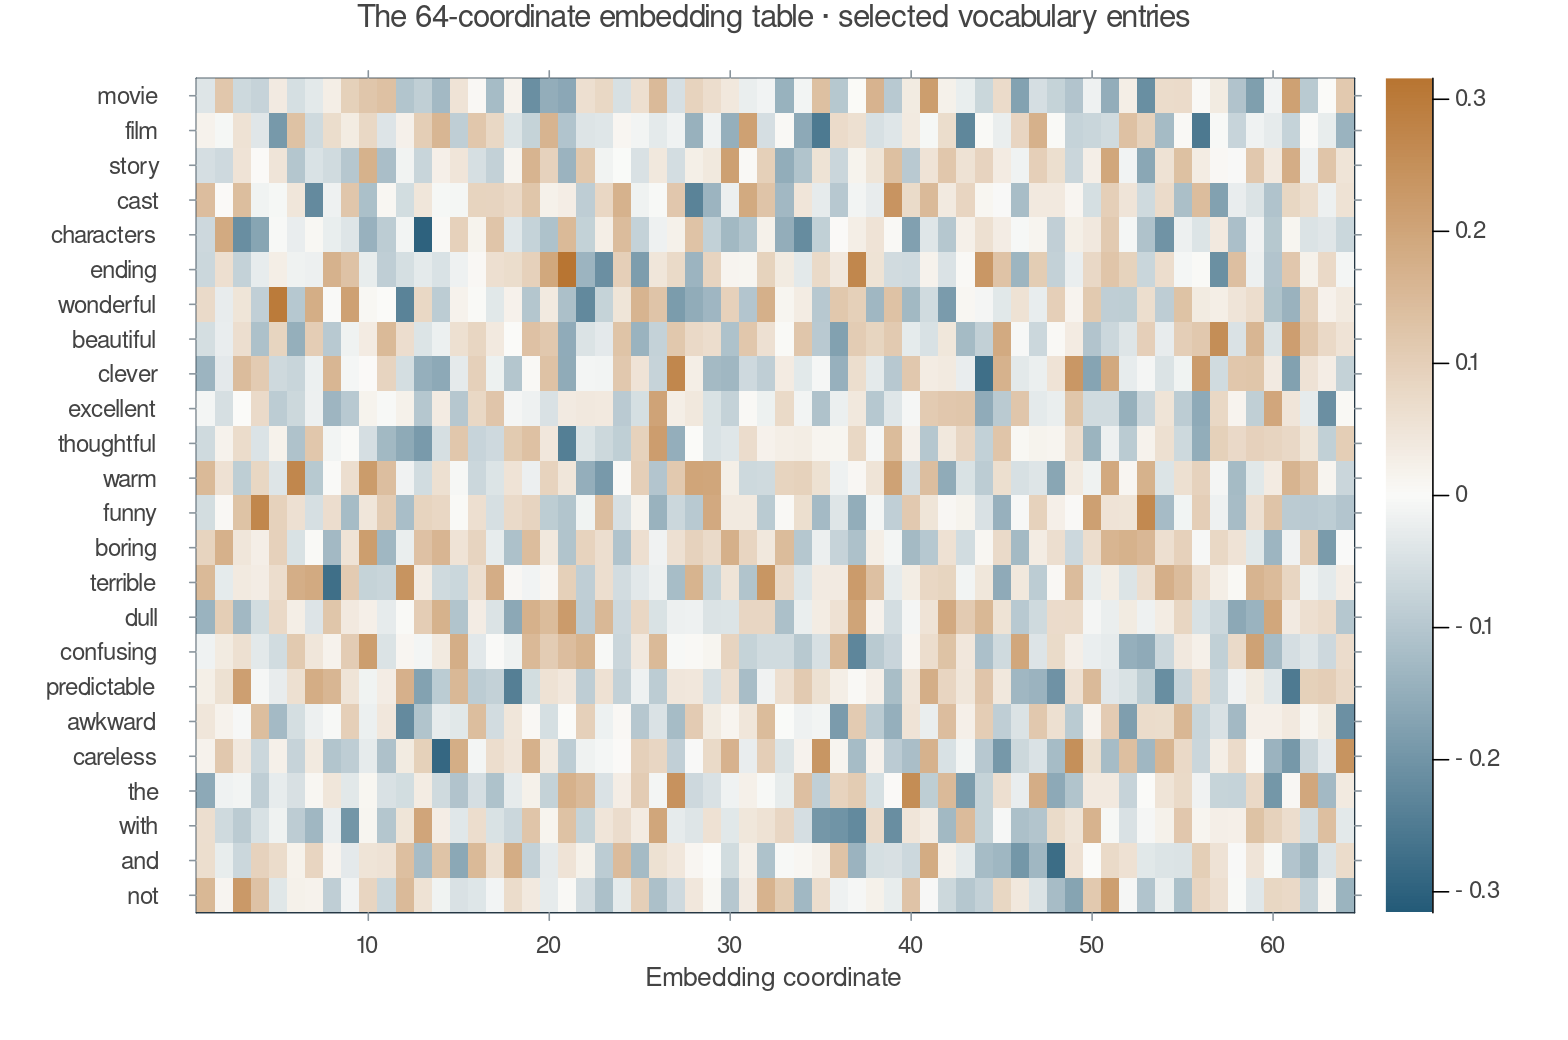

In [5]:
shown_words=["movie","film","story","cast","characters","ending","wonderful","beautiful",
    "clever","excellent","thoughtful","warm","funny","boring","terrible","dull",
    "confusing","predictable","awkward","careless","the","with","and","not"]
shown_words=filter(w->haskey(imdb.lookup,w),shown_words)
shown_ids=[imdb.lookup[w] for w in shown_words]
matrix_panel(classifier_initial.E[:,shown_ids]';rowlabels=shown_words,
    title="The 64-coordinate embedding table · selected vocabulary entries",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,650))

*Figure 1. Selected entries from the actual 64 × 20,000 initial table. All 64 coordinates are shown; the displayed words are only a view into the full vocabulary.*

### 2.2 Look up one vector for every token position

For the selected review, token position $t$ contains vocabulary ID $x_t$.
Define its looked-up vector as $\tilde e_t=e_{x_t}=E[:,x_t]$.
Collect the vectors in a new matrix:

$$H=\begin{bmatrix}\tilde e_1&\cdots&\tilde e_T\end{bmatrix}
  \in\mathbb R^{64\times T},\qquad H_{rt}=E_{r,x_t}.$$

$E$ stores a vector for **every vocabulary entry**.
$H$ contains the vectors selected by **this review**, in token order.
If the same token ID appears twice, two columns of $H$ refer to the same column of $E$.
The lookup is not a separate learned transformation: the entries of $E$ are the parameters.

In [6]:
trace_H=classifier_initial.E[:,trace_ids]
@assert size(trace_H)==(64,T_review)
println("H has shape ",size(trace_H),": 64 coordinates × ",T_review," token positions.")
println("First five coordinates of the first three token vectors:")
for t in 1:3
    @printf("%-12s ID=%5d  %s\n",trace_tokens[t],trace_ids[t],
        string(round.(trace_H[1:5,t];digits=4)))
end

H has shape (64, 115): 64 coordinates × 115 token positions.
First five coordinates of the first three token vectors:
this         ID=   11  Float32[0.149, -0.0328, 0.063, -0.0313, -0.0949]
film         ID=   19  Float32[0.0198, -0.0067, 0.0576, -0.039, -0.1927]
was          ID=   13  Float32[0.0585, 0.0074, 0.0966, 0.059, 0.0543]


### 2.3 Mean pooling: average across tokens, coordinate by coordinate

The neural classifier needs one fixed-length vector, although reviews have different $T$.
We choose **mean pooling**. Define the review vector $a\in\mathbb R^{64}$ by

$$a=\frac{1}{T}\sum_{t=1}^T\tilde e_t
    =\frac{1}{T}\sum_{t=1}^T E[:,x_t]
    =\frac{1}{T}H\mathbf1_T.$$

Here $\mathbf1_T$ is a $T$-vector of ones. Written one coordinate at a time,

$$a_r=\frac{E_{r,x_1}+E_{r,x_2}+\cdots+E_{r,x_T}}{T},
  \qquad r=1,\ldots,64.$$

So $a_1$ averages coordinate 1 over all tokens, $a_2$ averages coordinate 2, and so on.
We average **along the token-position axis**, keeping 64 separate coordinates.
Mean pooling is a modeling choice; it is not part of the definition of an embedding.

Repeated words can be counted instead of looked up repeatedly. For vocabulary ID $j$, define

$$n_j=\sum_{t=1}^T\mathbf1\{x_t=j\},\qquad
  f_j=\frac{n_j}{T},\qquad
  f=(f_1,\ldots,f_V)^\top\in\mathbb R^V.$$

$n_j$ is a count and $f_j$ is the fraction of review tokens with ID $j$.
Regrouping the same sum gives

$$a=\sum_{j=1}^V f_j e_j=Ef,\qquad \sum_{j=1}^V f_j=1.$$

For a batch of $B$ reviews, place their frequency vectors in
$F=[f^{(1)},\ldots,f^{(B)}]\in\mathbb R^{V\times B}$.
Then $EF\in\mathbb R^{64\times B}$ contains all their means.
$F$ is observed input data, not a trainable matrix. Most entries are zero, so sparse storage
makes this exact calculation efficient without discarding any words.

In [7]:
function word_frequencies(sequences,V;T=Float32)
    rows,cols,vals=Int[],Int[],T[]
    for (j,ids) in enumerate(sequences)
        append!(rows,ids);append!(cols,fill(j,length(ids)))
        append!(vals,fill(one(T)/length(ids),length(ids)))
    end
    sparse(rows,cols,vals,V,length(sequences))
end

function add_frequencies(data,V)
    (;data...,F=word_frequencies(data.ids,V))
end
imdb=merge(imdb,(training=add_frequencies(imdb.training,V_review),
    validation=add_frequencies(imdb.validation,V_review),
    test=add_frequencies(imdb.test,V_review)))
trace_f=imdb.training.F[:,trace_at:trace_at]
trace_mean=vec(mean(trace_H;dims=2))
@assert trace_mean≈vec(classifier_initial.E*trace_f)
@assert isapprox(sum(trace_f),1f0;atol=1f-6)
coordinate=7
@printf("Coordinate %d: sum across %d tokens = %.6f; divide by %d → %.6f\n",
    coordinate,T_review,sum(trace_H[coordinate,:]),T_review,trace_mean[coordinate])
@printf("f shape %s | E*f shape %s | all training means: 64 × %d\n",
    string(size(trace_f)),string(size(classifier_initial.E*trace_f)),length(imdb.training.rows))

Coordinate 7: sum across 115 tokens = -0.687907; divide by 115 → -0.005982
f shape (20000, 1) | E*f shape (64, 1) | all training means: 64 × 22411


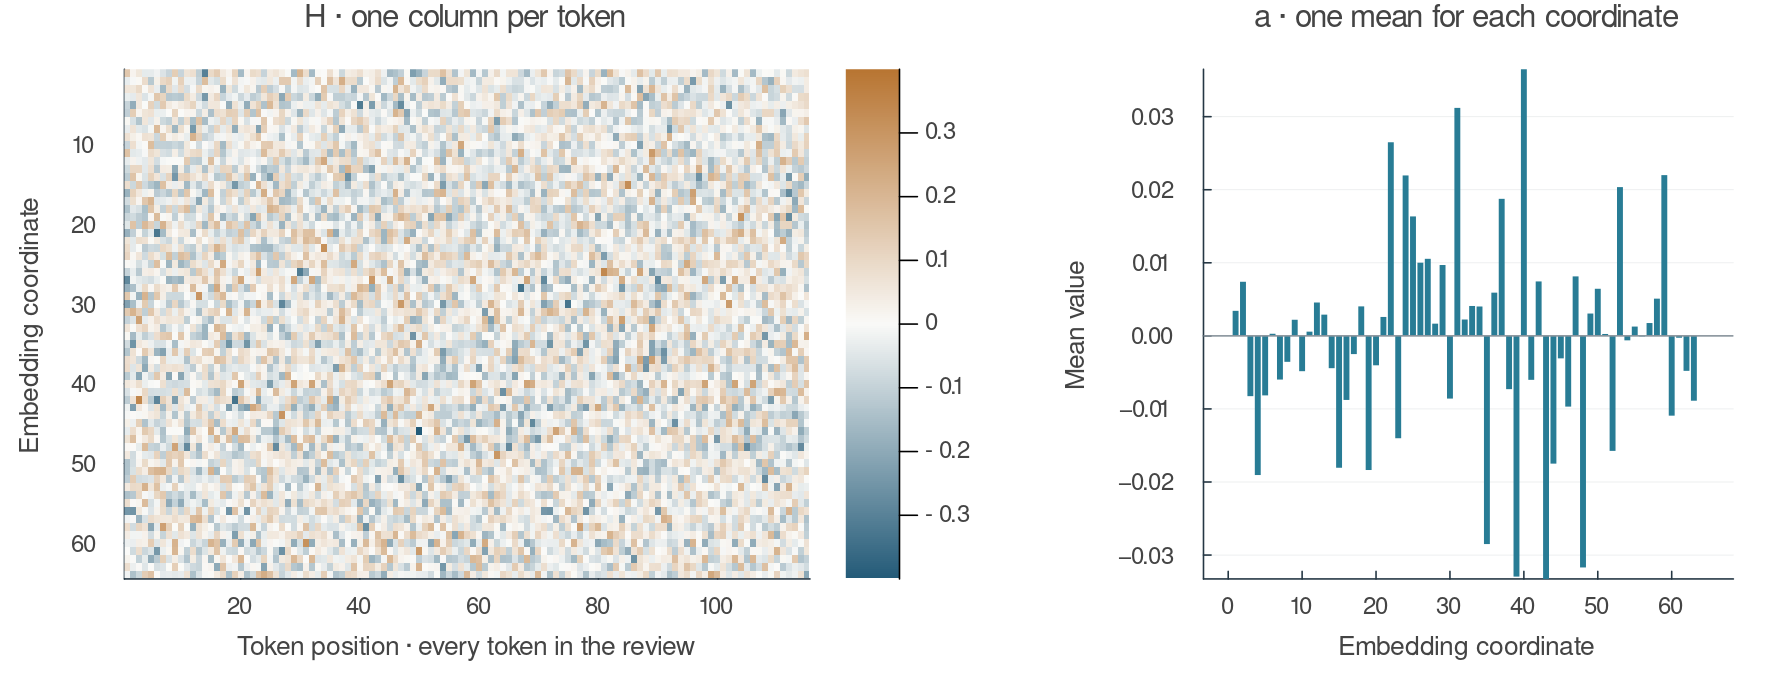

In [8]:
hp=heatmap(1:T_review,1:64,trace_H;color=DIV,
    clims=(-maximum(abs,trace_H),maximum(abs,trace_H)),colorbar=true,yflip=true,
    xlabel="Token position · every token in the review",ylabel="Embedding coordinate",
    title="H · one column per token",grid=false)
mp=bar(1:64,trace_mean;label=false,color=TEAL,linecolor=:transparent,
    xlabel="Embedding coordinate",ylabel="Mean value",
    title="a · one mean for each coordinate")
hline!(mp,[0];color=GRAY,lw=1,label=false)
plot(hp,mp;layout=grid(1,2,widths=[0.62,0.38]),size=(1120,430))

*Figure 2. Left: all token vectors of the selected real review. Averaging across its columns produces the 64 values on the right. The numerical check confirms that lookup-and-average and E times the frequency vector are the same operation.*

### 2.4 Transform the review vector with a hidden layer

Choose $m=64$ hidden units. Define a trainable weight matrix $W\in\mathbb R^{m\times d}$
and bias vector $b\in\mathbb R^m$. First compute the pre-activation vector $u$:

$$u=Wa+b\in\mathbb R^{64},\qquad
  u_k=\sum_{r=1}^{64}W_{kr}a_r+b_k,\quad k=1,\ldots,64.$$

Each hidden unit has its own weighted combination of all input coordinates.
Next apply the rectified linear unit (ReLU) to each coordinate:

$$h=\operatorname{ReLU}(u),\qquad h_k=\max(0,u_k).$$

$h\in\mathbb R^{64}$ is the hidden activation vector.
$d$ and $m$ are independent design choices; both happen to equal 64 here.
The nonlinearity lets the model learn a more flexible function than a single linear score.

### 2.5 Convert hidden activations into one probability

Define a trainable output vector $v\in\mathbb R^{64}$ and scalar bias $c\in\mathbb R$.
The output **logit** $z$ is

$$z=v^\top h+c=\sum_{k=1}^{64}v_kh_k+c\in\mathbb R.$$

It can be positive or negative and is not yet a probability. Apply the sigmoid function:

$$\hat p=\sigma(z)=\frac{1}{1+\exp(-z)}\in(0,1).$$

We predict “positive” when $\hat p\geq0.5$. The probability remains available even when
we do not convert it to a binary decision.
The code stores `v` as a $1\times64$ row matrix, so `v*h` implements $v^\top h$.
Each code column represents one review in a batch.

In [9]:
function review_forward(m,F)
    a=m.E*F
    u=m.W*a.+m.b
    h=max.(u,zero(eltype(u)))
    z=m.v*h.+m.c
    (;a,u,h,z,p=Flux.sigmoid.(z))
end
review_loss(m,F,y)=Flux.logitbinarycrossentropy(review_forward(m,F).z,y)

trace_target=imdb.training.y[:,trace_at:trace_at]
trace=review_forward(classifier_initial,trace_f)
@assert vec(trace.a)≈trace_mean
@assert trace.u[1]≈sum(classifier_initial.W[1,r]*trace_mean[r] for r in 1:64)+classifier_initial.b[1]
@assert only(trace.z)≈sum(classifier_initial.v[1,k]*trace.h[k] for k in 1:64)+only(classifier_initial.c)
println("a → u → h → z → probability shapes:")
println(size(trace.a)," → ",size(trace.u)," → ",size(trace.h)," → ",size(trace.z)," → ",size(trace.p))
@printf("Hidden unit 1: weighted sum + bias = %.6f; ReLU → %.6f\n",trace.u[1],trace.h[1])
@printf("Output: v' * h + c = %.6f; sigmoid → P(positive) = %.6f\n",only(trace.z),only(trace.p))

a → u → h → z → probability shapes:
(64, 1) → (64, 1) → (64, 1) → (1, 1) → (1, 1)
Hidden unit 1: weighted sum + bias = -0.002281; ReLU → 0.000000
Output: v' * h + c = 0.002523; sigmoid → P(positive) = 0.500631


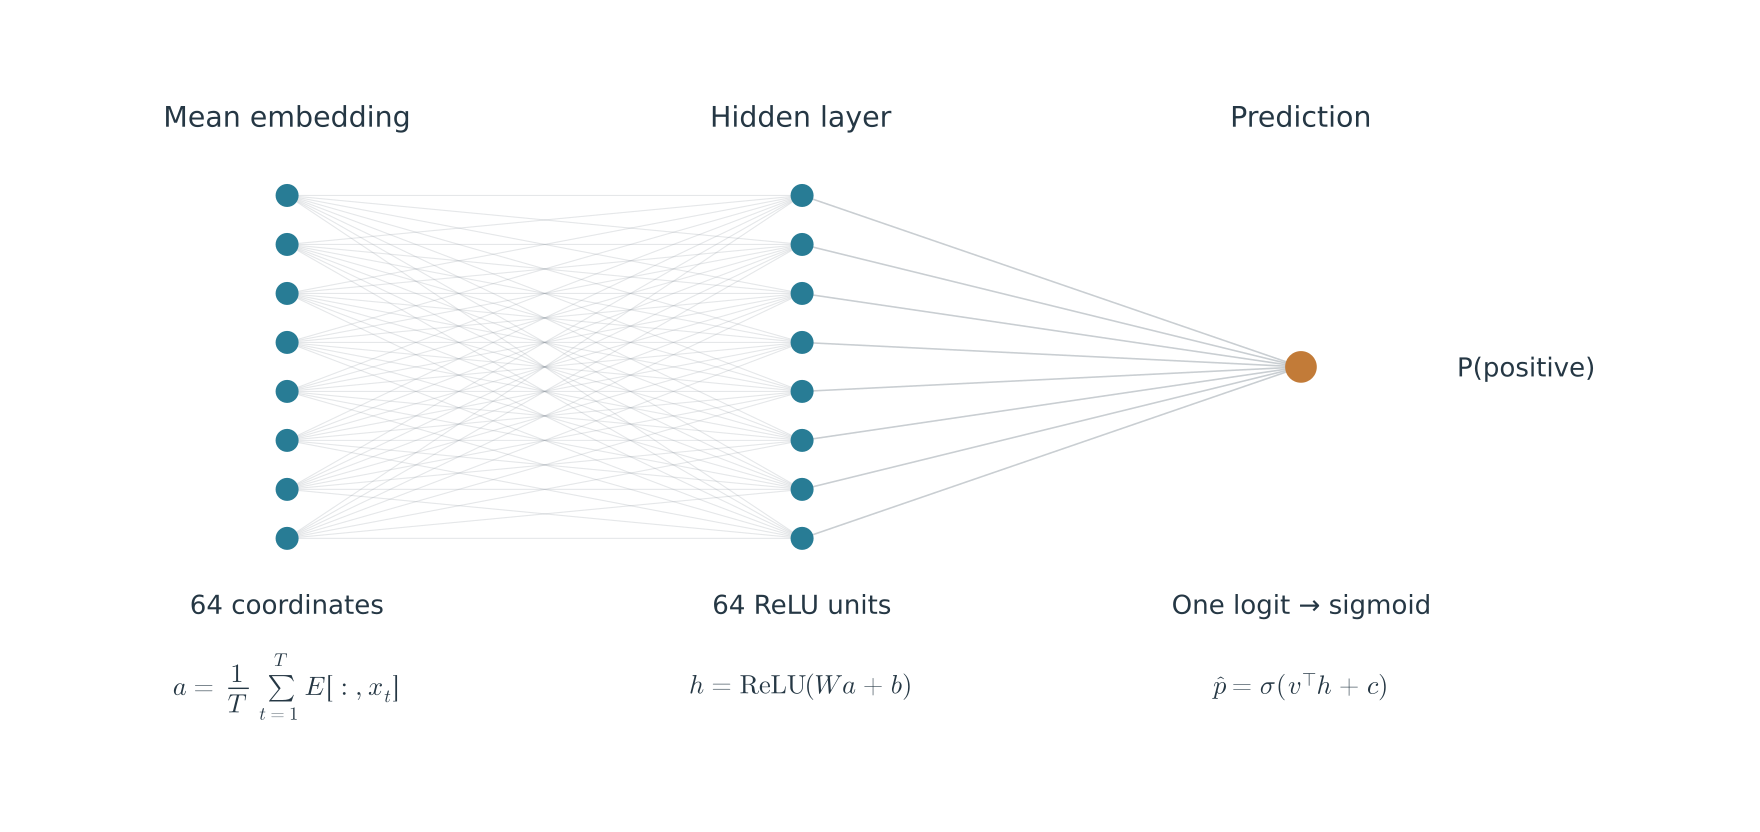

In [10]:
function classifier_diagram(d=64,hidden=64)
    p=plot(xlims=(0,10),ylims=(-1.6,8.8),axis=false,grid=false,legend=false,size=(1100,520))
    xs=[1.2,4.4,7.5];ys=collect(range(1.4,6.6;length=8))
    for a in ys,b in ys
        plot!(p,[xs[1],xs[2]],[a,b];color=GRAY,alpha=0.22,lw=0.7)
    end
    for a in ys
        plot!(p,[xs[2],xs[3]],[a,4];color=GRAY,alpha=0.45,lw=1)
    end
    scatter!(p,fill(xs[1],8),ys;ms=8,color=TEAL,markerstrokewidth=0)
    scatter!(p,fill(xs[2],8),ys;ms=8,color=TEAL,markerstrokewidth=0)
    scatter!(p,[xs[3]],[4];ms=11,color=AMBER,markerstrokewidth=0)
    annotate!(p,1.2,7.8,text("Mean embedding",12,INK))
    annotate!(p,4.4,7.8,text("Hidden layer",12,INK))
    annotate!(p,7.5,7.8,text("Prediction",12,INK))
    annotate!(p,1.2,0.4,text("$d coordinates",11,INK))
    annotate!(p,4.4,0.4,text("$hidden ReLU units",11,INK))
    annotate!(p,7.5,0.4,text("One logit → sigmoid",11,INK))
    annotate!(p,1.2,-0.85,text(L"a=\frac{1}{T}\sum_{t=1}^{T}E[:,x_t]",11,INK))
    annotate!(p,4.4,-0.85,text(L"h=\mathrm{ReLU}(Wa+b)",11,INK))
    annotate!(p,8.9,4,text("P(positive)",11,INK))
    annotate!(p,7.5,-0.85,text(L"\hat{p}=\sigma(v^\top h+c)",11,INK))
    p
end

classifier_diagram()

*Figure 3. The actual classifier has 64 mean-embedding coordinates and 64 hidden units. Eight representative nodes per layer make the connections readable; all 64 coordinates participate in the computation. The mean, hidden-layer, and output formulas appear directly in the figure.*

### 2.6 Keep parameters and activations separate

| Object | Shape for one review | Role |
|---|---|---|
| $x_1,\ldots,x_T$, $y$ | $T$ IDs and one label | Observed data |
| $E$ | $64\times20{,}000$ | Trainable vocabulary embedding table |
| $W,b$ | $64\times64$, $64$ | Trainable hidden-layer weights and biases |
| $v,c$ | $64$, scalar | Trainable output weights and bias |
| $H,a,u,h,z,\hat p$ | As defined above | Activations recomputed for this input |

The complete parameter collection is $\theta=(E,W,b,v,c)$, with

$$\underbrace{64(20{,}000)}_{E}
+\underbrace{64(64)}_W+\underbrace{64}_b+\underbrace{64}_v+\underbrace{1}_c
=1{,}284{,}225\text{ parameters}.$$

The forward pass reads $\theta$ and produces activations. It does not change the parameters.

## 3. From prediction error to parameter updates

### 3.1 Define a loss for one observed review

For label $y\in\{0,1\}$ and predicted probability $\hat p$, define binary cross-entropy:

$$L(\theta;s,y)=-y\log\hat p-(1-y)\log(1-\hat p)
=\begin{cases}-\log\hat p&y=1,\\-\log(1-\hat p)&y=0.\end{cases}$$

The loss is small when the model assigns high probability to the observed label.
It becomes large when the prediction is confidently wrong.
The code uses the equivalent, numerically stable loss computed directly from logits.

In [11]:
L_review=review_loss(classifier_initial,trace_f,trace_target)
manual_L=-only(trace_target)*log(only(trace.p))-(1-only(trace_target))*log1p(-only(trace.p))
@assert isapprox(L_review,manual_L;atol=1f-6)
@printf("Observed y = %d; predicted p = %.6f; cross-entropy = %.6f\n",
    trace_row.y,only(trace.p),L_review)

Observed y = 0; predicted p = 0.500631; cross-entropy = 0.694410


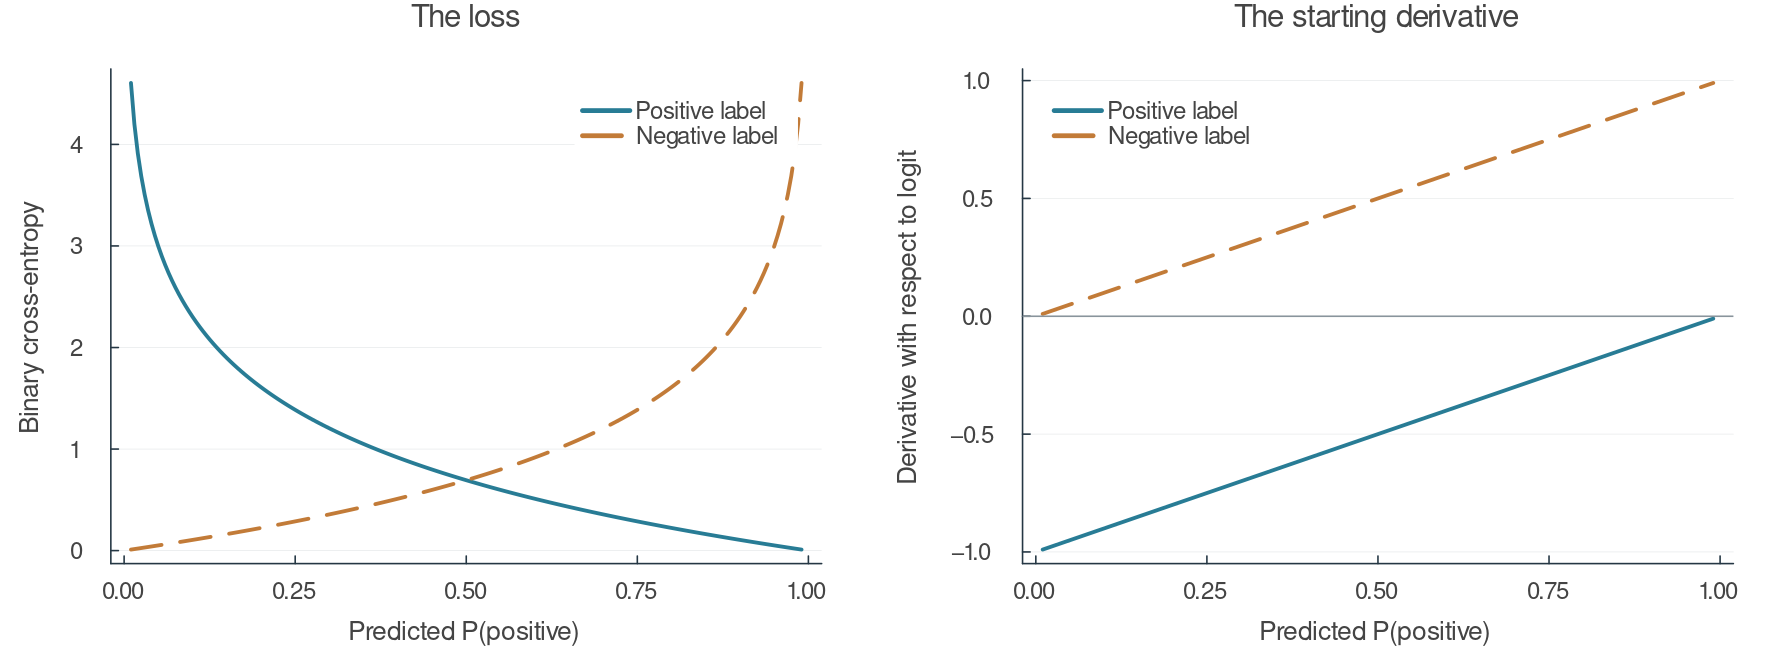

In [12]:
prob_grid=collect(0.01:0.005:0.99)
lp=plot(prob_grid,-log.(prob_grid);label="Positive label",color=TEAL,
    xlabel="Predicted P(positive)",ylabel="Binary cross-entropy",title="The loss")
plot!(lp,prob_grid,-log1p.(-prob_grid);label="Negative label",color=AMBER,linestyle=:dash)
gp=plot(prob_grid,prob_grid.-1;label="Positive label",color=TEAL,
    xlabel="Predicted P(positive)",ylabel="Derivative with respect to logit",title="The starting derivative")
plot!(gp,prob_grid,prob_grid;label="Negative label",color=AMBER,linestyle=:dash)
hline!(gp,[0];color=GRAY,label=false,lw=1)
plot(lp,gp;layout=(1,2),size=(1120,420))

*Figure 4. Left: how the probability affects cross-entropy. Right: the derivative with respect to the logit, derived next. The horizontal axis in both panels is the predicted probability.*

### 3.2 Differentiate the output, without skipping the sigmoid

For an intermediate vector $q$, write $\delta_q=\partial L/\partial q$.
Begin with the two scalar derivatives:

$$\frac{\partial L}{\partial\hat p}
=-\frac{y}{\hat p}+\frac{1-y}{1-\hat p},
\qquad
\frac{\partial\hat p}{\partial z}=\hat p(1-\hat p).$$

The chain rule gives

$$\delta_z=\frac{\partial L}{\partial z}
=\left(-\frac{y}{\hat p}+\frac{1-y}{1-\hat p}\right)\hat p(1-\hat p)
=-y(1-\hat p)+(1-y)\hat p
=\hat p-y.$$

For a positive review, $\delta_z<0$, so a small descent step on $z$ would raise it.
For a negative review, $\delta_z>0$, so descent would lower it.
The optimizer actually changes parameters; the derivatives below tell it how each parameter affects $z$.

### 3.3 Continue backward through the output and hidden layer

Since $z=\sum_k v_kh_k+c$,

$$\frac{\partial L}{\partial v_k}=\delta_z h_k,\qquad
  \frac{\partial L}{\partial c}=\delta_z,\qquad
  (\delta_h)_k=\delta_z v_k.$$

For ReLU, a positive pre-activation has derivative 1 and a negative one has derivative 0.
We use derivative 0 at its kink, $u_k=0$. Therefore

$$\delta_u=\delta_h\odot\mathbf1_{\{u>0\}},$$

where $\odot$ means coordinate-by-coordinate multiplication.
Using $u_k=\sum_r W_{kr}a_r+b_k$, each derivative is

$$\frac{\partial L}{\partial W_{kr}}=(\delta_u)_k a_r,\qquad
  \frac{\partial L}{\partial b_k}=(\delta_u)_k,\qquad
  (\delta_a)_r=\sum_{k=1}^{64}W_{kr}(\delta_u)_k.$$

In matrix form:

$$\nabla_W L=\delta_u a^\top,\qquad
  \nabla_b L=\delta_u,\qquad
  \delta_a=W^\top\delta_u.$$

### 3.4 Continue through the average to the embedding table

Recall the exact scalar mean $a_r=\sum_j f_jE_{rj}$.
The frequencies $f_j$ are fixed for this review, so

$$\frac{\partial a_r}{\partial E_{rj}}=f_j=\frac{n_j}{T},\qquad
  \frac{\partial L}{\partial E_{rj}}=(\delta_a)_r\frac{n_j}{T}.$$

Across all coordinates and vocabulary entries,

$$\nabla_E L=\delta_a f^\top\in\mathbb R^{64\times20{,}000},
  \qquad \nabla_{E[:,j]}L=\frac{n_j}{T}\delta_a.$$

An unused word has $n_j=0$, hence zero gradient for this review.
A repeated word contributes through every occurrence.
Even a neutral word can move after one example; learning across many reviews separates
predictive patterns from incidental co-occurrence.
**There is no target embedding to copy. The prediction loss supplies its training signal.**

### 3.5 Apply one simultaneous parameter update

Let $\eta>0$ be the learning rate. Plain gradient descent applies

$$\theta_{\mathrm{new}}=\theta_{\mathrm{old}}
  -\eta\nabla_\theta L(\theta_{\mathrm{old}}).$$

For one embedding entry, this is explicitly

$$E_{rj}^{\mathrm{new}}
=E_{rj}^{\mathrm{old}}
-\eta\left[\frac{n_j}{T}(\delta_a)_r\right]_{\theta=\theta_{\mathrm{old}}}.$$

All derivatives are computed using the **old** parameters before any are updated.
Backpropagation computes gradients; the optimizer uses them to update parameters.
Activations such as $a$ and $h$ are recomputed on the next forward pass, not stored as learned parameters.

The cell below calculates every derivative by hand, checks it against Flux automatic
differentiation on the full model, and prints the actual numbers for one embedding update.
It leaves the original initialization intact for the training experiment.

Manual / AD maximum difference: 0.00e+00
One step on the full model: loss 0.694410 → 0.657733
Token 'the', ID 2, occurs 9/115 times
E[7,2]: 0.0094454 − 0.1 × (0.0099652) = 0.0084489
19920 unused vocabulary entries have exactly zero embedding gradient for this review.


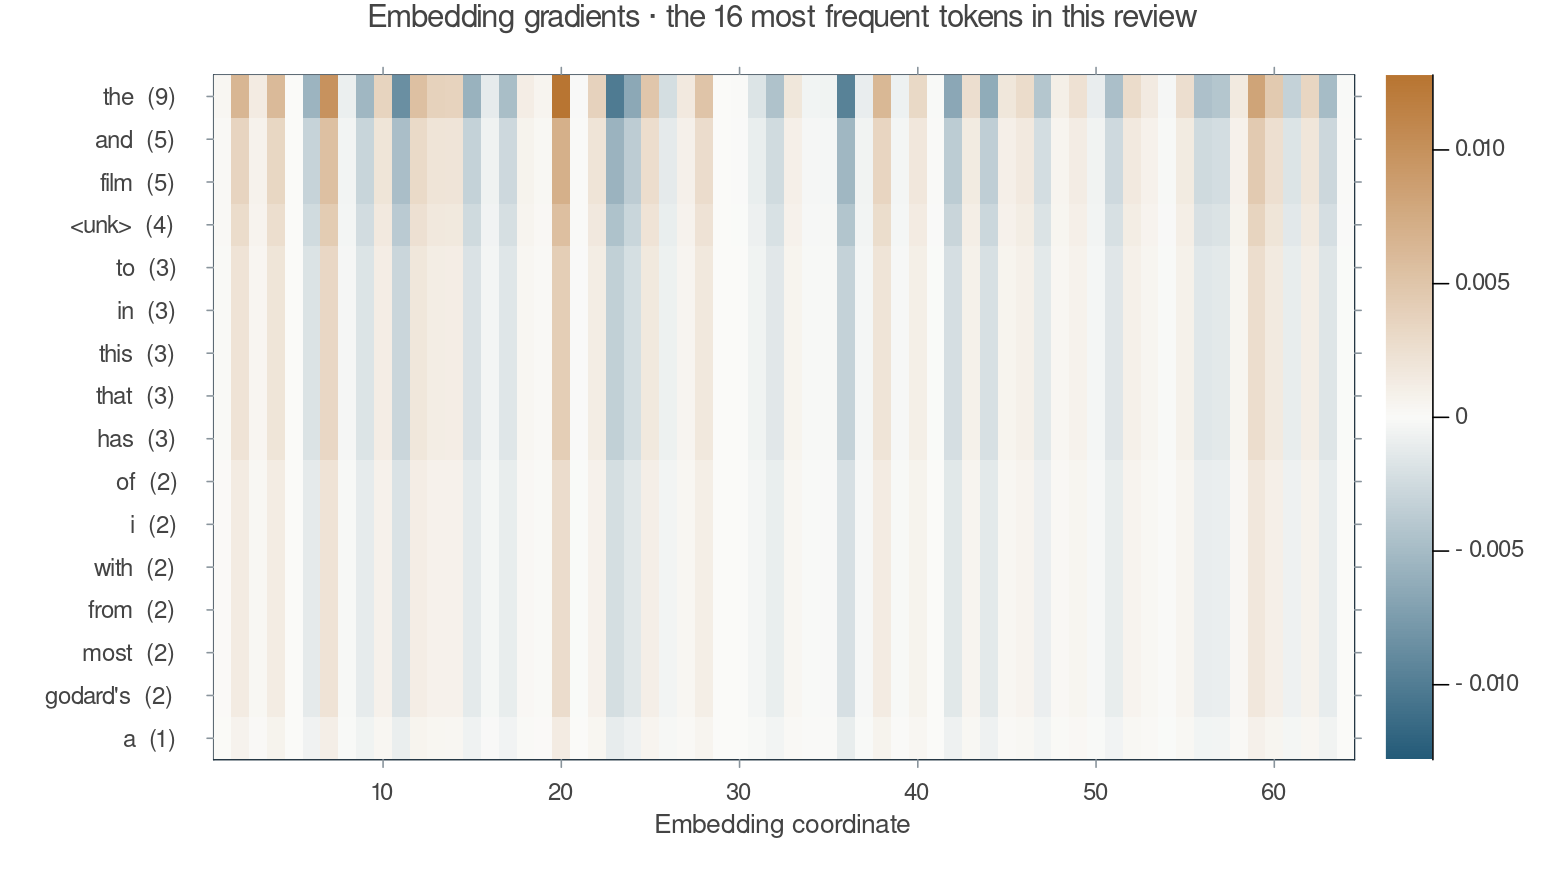

In [13]:
delta_z=trace.p-trace_target
delta_h=classifier_initial.v'*delta_z
delta_u=delta_h.*(trace.u.>0)
delta_a=classifier_initial.W'*delta_u
manual_gradient=(E=Matrix(delta_a*trace_f'),W=delta_u*trace.a',
    b=vec(delta_u),v=delta_z*trace.h',c=vec(delta_z))
ad_gradient=Flux.gradient(m->review_loss(m,trace_f,trace_target),classifier_initial)[1]
gradient_error=maximum(maximum(abs.(getproperty(manual_gradient,k).-getproperty(ad_gradient,k)))
    for k in keys(classifier_initial))
@assert gradient_error<2f-6
unused=setdiff(1:V_review,trace_ids)
@assert all(iszero,ad_gradient.E[:,unused])
eta=0.1f0
one_step=map((p,g)->p.-eta.*g,classifier_initial,ad_gradient)
@assert review_loss(one_step,trace_f,trace_target)<L_review
word_counts=Dict(j=>count(==(j),trace_ids) for j in unique(trace_ids))
gradient_ids=sort(collect(keys(word_counts));by=j->(-word_counts[j],j))[1:16]
focus_id=first(gradient_ids);r=7
@printf("Manual / AD maximum difference: %.2e\n",gradient_error)
@printf("One step on the full model: loss %.6f → %.6f\n",
    L_review,review_loss(one_step,trace_f,trace_target))
@printf("Token '%s', ID %d, occurs %d/%d times\n",
    imdb.vocab[focus_id],focus_id,word_counts[focus_id],T_review)
@printf("E[7,%d]: %.7f − %.1f × (%.7f) = %.7f\n",
    focus_id,classifier_initial.E[r,focus_id],eta,ad_gradient.E[r,focus_id],one_step.E[r,focus_id])
@printf("%d unused vocabulary entries have exactly zero embedding gradient for this review.\n",length(unused))
gradient_labels=[string(imdb.vocab[j],"  (",word_counts[j],")") for j in gradient_ids]
matrix_panel(ad_gradient.E[:,gradient_ids]';rowlabels=gradient_labels,
    title="Embedding gradients · the 16 most frequent tokens in this review",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,550))

*Figure 5. A real review produces gradients in the full 64 × 20,000 table. The displayed rows are its 16 most frequent vocabulary IDs; parentheses give occurrence counts. Repeated words receive proportionally larger contributions. The code also verifies zero gradients for every unused entry.*

## 4. Train and evaluate the IMDb network

### 4.1 Average gradients across a batch

For a batch $\mathcal B$ of $B$ reviews, the objective and its derivative are

$$L_{\mathcal B}(\theta)=\frac1B\sum_{n\in\mathcal B}L(\theta;s_n,y_n),
\qquad
\nabla_\theta L_{\mathcal B}=\frac1B\sum_{n\in\mathcal B}\nabla_\theta L_n.$$

The training loop shuffles the training reviews, takes batches of 128, computes this mean loss,
backpropagates, and updates all parameters. One **epoch** visits every training review once.
The last batch can be smaller than 128.

We use Adam instead of plain gradient descent for the full fit. For update index $q$ and
batch gradient $g_q$, Adam keeps two running arrays, initially $m_0=v_0=0$:

$$m_q=\beta_1m_{q-1}+(1-\beta_1)g_q,\qquad
  v_q=\beta_2v_{q-1}+(1-\beta_2)(g_q\odot g_q).$$

With bias correction $\hat m_q=m_q/(1-\beta_1^q)$ and
$\hat v_q=v_q/(1-\beta_2^q)$, its update is

$$\theta_q=\theta_{q-1}
-\eta\frac{\hat m_q}{\sqrt{\hat v_q}+\epsilon}.$$

All operations in this update are coordinatewise; $\beta_1,\beta_2\in[0,1)$ control smoothing
and $\epsilon>0$ stabilizes the denominator. These optimizer arrays are distinct from the
classifier's output vector $v$. Adam changes the update rule, not the forward equations or chain rule.

### 4.2 Fit the same 1.28-million-parameter model

The fit starts from the exact initialization used above.
It uses eight epochs, learning rate 0.003, and all tokenized words in every review.
After each epoch, validation cross-entropy determines whether to keep that checkpoint.
Only after selection is the test set evaluated.

`TRAIN_SENTIMENT=true` retrains the model; false loads its saved result.
The ten-minute fit budget is checked between updates; setup and final evaluation add time.

In [14]:
function evaluate_reviews(m,data;batch_size=512)
    probabilities=Float32[];total=0.0
    for start in 1:batch_size:length(data.rows)
        idx=start:min(start+batch_size-1,length(data.rows))
        trace=review_forward(m,data.F[:,idx])
        append!(probabilities,vec(trace.p))
        total+=Float64(Flux.logitbinarycrossentropy(trace.z,data.y[:,idx]))*length(idx)
    end
    truth=vec(data.y).==1;pred=probabilities.>=0.5
    cm=[sum((truth.==a).&(pred.==p)) for a in (false,true),p in (false,true)]
    (;loss=total/length(truth),accuracy=mean(truth.==pred),probabilities,confusion=cm,
      f1=2cm[2,2]/max(2cm[2,2]+cm[1,2]+cm[2,1],1))
end
function train_reviews(data;d=64,hidden=64,epochs=8,batch_size=128,lr=0.003f0,budget=600)
    started=time();initial=deepcopy(classifier_initial)
    @assert size(initial.E)==(d,length(data.vocab)) && size(initial.W)==(hidden,d)
    m=deepcopy(initial);opt=Flux.setup(Flux.Adam(lr),m);rng=MersenneTwister(2719)
    tr,va=evaluate_reviews(m,data.training),evaluate_reviews(m,data.validation)
    history=[(;epoch=0,train_loss=tr.loss,val_loss=va.loss,train_acc=tr.accuracy,val_acc=va.accuracy)]
    best,best_loss,best_epoch=deepcopy(m),va.loss,0
    for epoch in 1:epochs
        order=randperm(rng,length(data.training.rows))
        for start in 1:batch_size:length(order)
            time()-started>budget && break
            idx=order[start:min(start+batch_size-1,length(order))]
            F,y=data.training.F[:,idx],data.training.y[:,idx]
            loss,g=Flux.withgradient(p->review_loss(p,F,y),m)
            @assert isfinite(loss)
            Flux.update!(opt,m,g[1])
        end
        tr,va=evaluate_reviews(m,data.training),evaluate_reviews(m,data.validation)
        push!(history,(;epoch,train_loss=tr.loss,val_loss=va.loss,train_acc=tr.accuracy,val_acc=va.accuracy))
        if va.loss<best_loss
            best,best_loss,best_epoch=deepcopy(m),va.loss,epoch
        end
        @printf("Epoch %d | train %.3f | validation %.3f | val accuracy %.1f%%\n",
            epoch,tr.loss,va.loss,100va.accuracy)
        time()-started>budget && break
    end
    test=evaluate_reviews(best,data.test)
    (;model=best,initial,history,best_epoch,test,seconds=time()-started,
      vocab=data.vocab,config=(;d,hidden,epochs,batch_size,lr))
end
TRAIN_SENTIMENT=true
sentiment=TRAIN_SENTIMENT ? train_reviews(imdb) : deserialize(joinpath(RESULTS,"sentiment.jls"))
@assert sentiment.vocab==imdb.vocab
@assert sentiment.initial==classifier_initial
TRAIN_SENTIMENT && serialize(joinpath(RESULTS,"sentiment.jls"),sentiment)
@printf("%s parameters | selected epoch %d | fit %.1f seconds\n",
    string(sum(length,values(sentiment.model))),sentiment.best_epoch,sentiment.seconds)

Epoch 1 | train 0.178 | validation 0.263 | val accuracy 89.2%
Epoch 2 | train 0.106 | validation 0.268 | val accuracy 89.4%
Epoch 3 | train 0.056 | validation 0.294 | val accuracy 89.0%
Epoch 4 | train 0.038 | validation 0.361 | val accuracy 88.8%
Epoch 5 | train 0.021 | validation 0.450 | val accuracy 87.4%
Epoch 6 | train 0.007 | validation 0.505 | val accuracy 88.1%
Epoch 7 | train 0.003 | validation 0.581 | val accuracy 88.0%
Epoch 8 | train 0.002 | validation 0.623 | val accuracy 88.1%
1284225 parameters | selected epoch 1 | fit 8.7 seconds


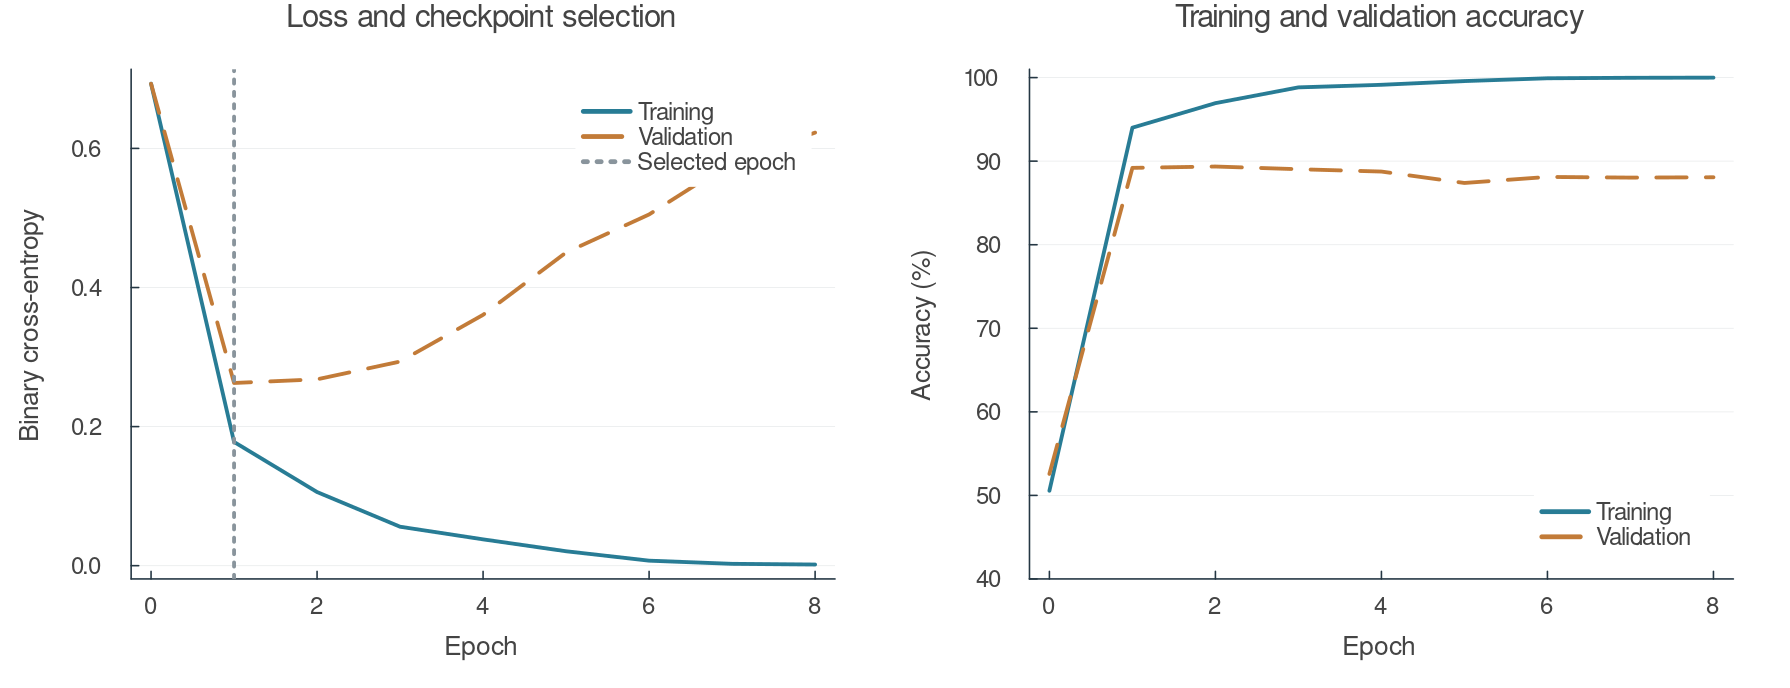

In [15]:
epochs=[h.epoch for h in sentiment.history]
p1=plot(epochs,[h.train_loss for h in sentiment.history];label="Training",color=TEAL,
    xlabel="Epoch",ylabel="Binary cross-entropy",title="Loss and checkpoint selection")
plot!(p1,epochs,[h.val_loss for h in sentiment.history];label="Validation",color=AMBER,linestyle=:dash)
vline!(p1,[sentiment.best_epoch];label="Selected epoch",color=GRAY,linestyle=:dot)
p2=plot(epochs,100 .* [h.train_acc for h in sentiment.history];label="Training",color=TEAL,
    xlabel="Epoch",ylabel="Accuracy (%)",ylims=(40,101),title="Training and validation accuracy")
plot!(p2,epochs,100 .* [h.val_acc for h in sentiment.history];label="Validation",color=AMBER,linestyle=:dash)
plot(p1,p2;layout=(1,2),size=(1120,430))

*Figure 6. Training and validation use different reviews. Falling training loss can coexist with rising validation loss; the dotted line identifies the selected checkpoint.*

### 4.3 Measure performance and inspect mistakes

Let $\hat y_n=\mathbf1\{\hat p_n\geq0.5\}$ and let $N_{\rm test}$ be the number of test reviews.

$$\mathrm{Accuracy}=\frac1{N_{\rm test}}\sum_n\mathbf1\{\hat y_n=y_n\}.$$

A **true positive** (TP) is a positive review predicted positive.
A **false positive** (FP) is a negative review predicted positive.
A **false negative** (FN) is a positive review predicted negative.
Positive-class F1 combines these counts:

$$F_1=\frac{2TP}{2TP+FP+FN}.$$

The confusion matrix uses actual labels in rows and predicted labels in columns.
We also compare accuracy with the majority-label rule selected from training labels.

Filtered test: 24675 reviews | accuracy 87.78% | positive F1 0.8730 | loss 0.2969
Training-majority baseline: 50.30%


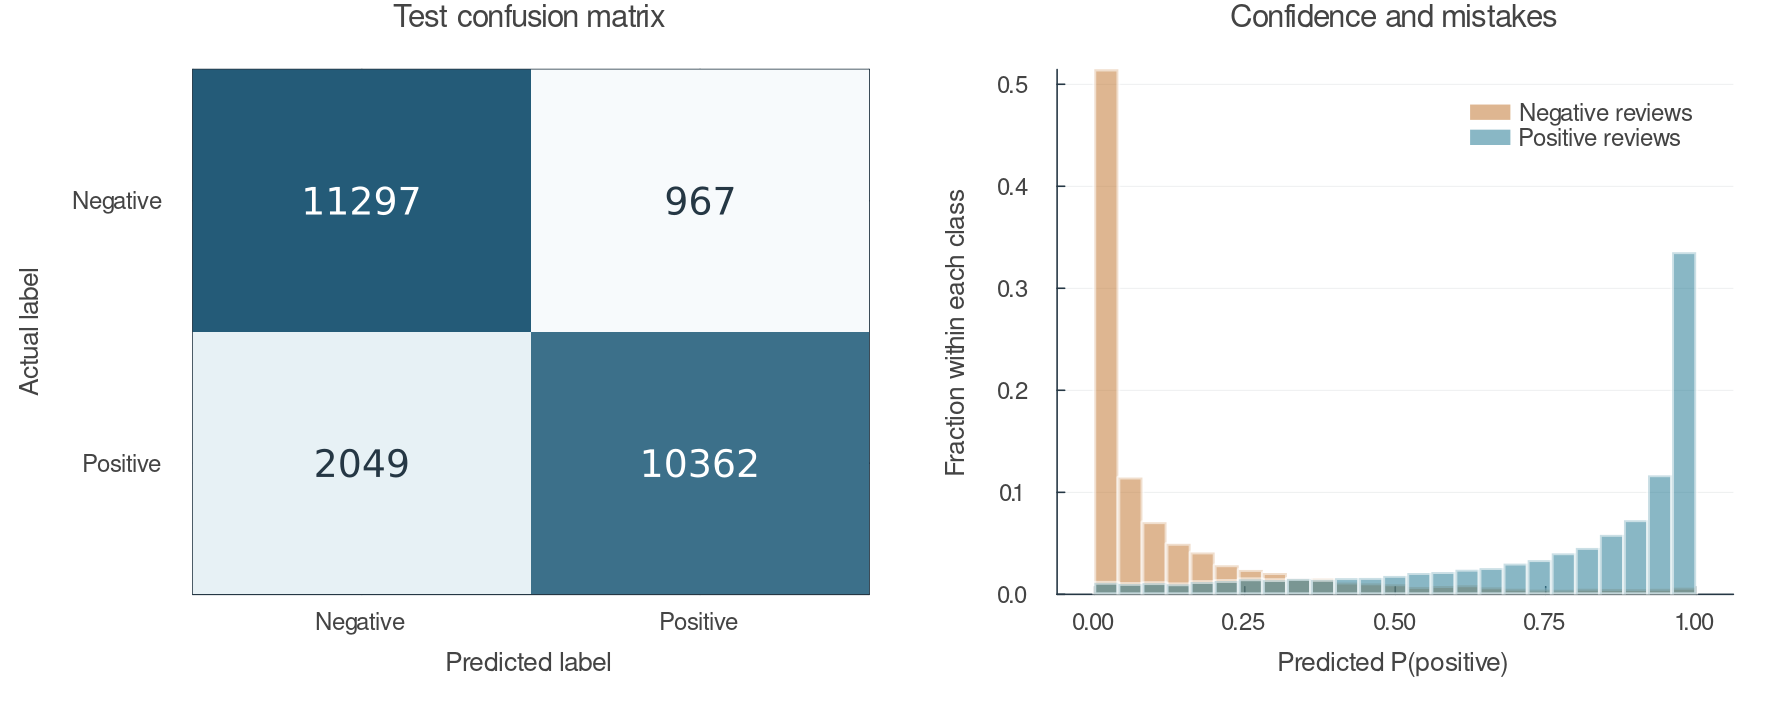

In [16]:
cm=sentiment.test.confusion
@printf("Filtered test: %d reviews | accuracy %.2f%% | positive F1 %.4f | loss %.4f\n",
    length(imdb.test.rows),100sentiment.test.accuracy,sentiment.test.f1,sentiment.test.loss)
majority=mean(imdb.training.y)>=0.5
@printf("Training-majority baseline: %.2f%%\n",100mean((vec(imdb.test.y).>=0.5).==majority))
cp=heatmap(1:2,1:2,cm;color=SEQ,colorbar=false,yflip=true,grid=false,framestyle=:box,
    xticks=(1:2,["Negative","Positive"]),yticks=(1:2,["Negative","Positive"]),
    xlabel="Predicted label",ylabel="Actual label",title="Test confusion matrix")
for a in 1:2,p in 1:2
    annotate!(cp,p,a,text(string(cm[a,p]),16,cm[a,p]>maximum(cm)/2 ? :white : INK))
end
neg=sentiment.test.probabilities[vec(imdb.test.y).==0]
pos=sentiment.test.probabilities[vec(imdb.test.y).==1]
hp=histogram(neg;bins=0:0.04:1,normalize=:probability,color=AMBER,alpha=0.55,
    linecolor=:white,label="Negative reviews",xlabel="Predicted P(positive)",
    ylabel="Fraction within each class",title="Confidence and mistakes")
histogram!(hp,pos;bins=0:0.04:1,normalize=:probability,color=TEAL,alpha=0.55,
    linecolor=:white,label="Positive reviews")
plot(cp,hp;layout=(1,2),size=(1120,440))

*Figure 7. The matrix reports counts. Each probability histogram is normalized within its actual class, making confident errors and ambiguous predictions visible.*

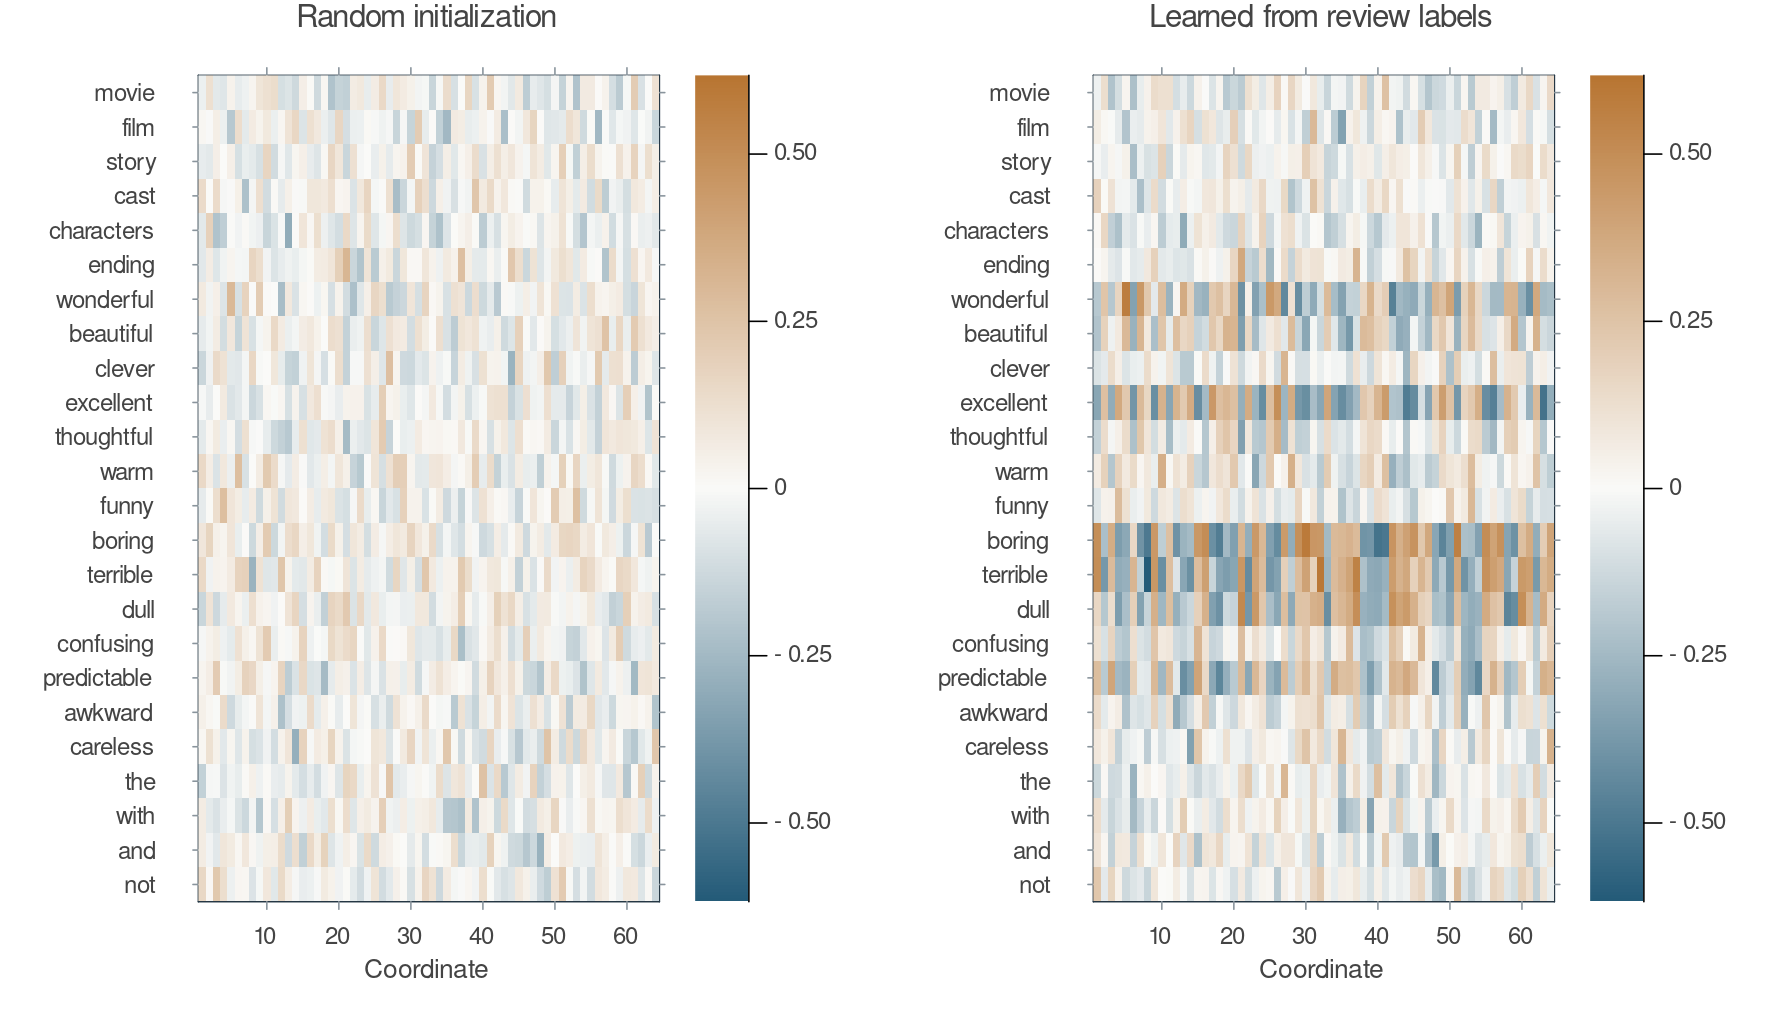

In [17]:
real_words=filter(w->haskey(imdb.lookup,w),shown_words)
real_ids=[imdb.lookup[w] for w in real_words]
E0,E1=sentiment.initial.E[:,real_ids]',sentiment.model.E[:,real_ids]'
scale=max(maximum(abs,E0),maximum(abs,E1))
ep0=matrix_panel(E0;rowlabels=real_words,title="Random initialization",limit=scale)
ep1=matrix_panel(E1;rowlabels=real_words,title="Learned from review labels",limit=scale)
plot(ep0,ep1;layout=(1,2),size=(1120,640))

*Figure 8. The same entries in the same full embedding table before and after fitting, with common color limits. All 64 coordinates are displayed.*

In [18]:
function sentiment_probability(text,run=sentiment)
    lookup=Dict(w=>i for (i,w) in enumerate(run.vocab))
    ids=word_ids(text,lookup)
    only(review_forward(run.model,word_frequencies([ids],length(run.vocab))).p)
end
my_reviews=["The actors were wonderful and the story kept me interested.",
    "The plot was confusing and the dialogue was painfully dull.",
    "The movie is good, not bad.","The movie is bad, not good."]
for s in my_reviews
    @printf("P(positive) = %.4f | %s\n",sentiment_probability(s),s)
end
@assert sentiment_probability(my_reviews[3])≈sentiment_probability(my_reviews[4])
mistakes=findall((sentiment.test.probabilities.>=0.5).!=(vec(imdb.test.y).>=0.5))
println("\nFirst two errors in source order (short excerpts):")
for i in first(mistakes,2)
    @printf("label=%d, P(positive)=%.3f: %s…\n",imdb.test.rows[i].y,
        sentiment.test.probabilities[i],first(replace(imdb.test.rows[i].text,r"<[^>]*>"=>" "),130))
end

P(positive) = 0.9980 | The actors were wonderful and the story kept me interested.
P(positive) = 0.0000 | The plot was confusing and the dialogue was painfully dull.
P(positive) = 0.0003 | The movie is good, not bad.
P(positive) = 0.0003 | The movie is bad, not good.

First two errors in source order (short excerpts):
label=0, P(positive)=0.951: First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of th…
label=0, P(positive)=0.589: Blind Date (Columbia Pictures, 1934), was a decent film, but I have a few issues with this film. First of all, I don't fault the a…


### 4.4 What averaging cannot represent

The two probe sentences `The movie is good, not bad` and `The movie is bad, not good`
have the same word counts. Therefore they have the same $f$, the same $a=Ef$,
and the same prediction, despite their different word order.
The code verifies this equality.

This is a limitation of this architecture, not a shortage of training epochs.
To model order and context, we need a representation that keeps a separate state at each position.
Short probes also differ from the full reviews used in training; their probabilities are not calibrated guarantees.

## 5. Change the target: predict the next token

### 5.1 The English corpus supplies its own labels

We now begin the second full project: a GPT-style language model on
[TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories),
a synthetic simple-English corpus.
The prepared training subset contains 81,694 stories and about 17.66 million tokens.
Validation and test come from the source's held-out split.
Preparation uses bounded corpus prefixes, ASCII normalization, and exact deduplication.

This project has its **own** vocabulary and embedding table.
It uses 2,048 BPE tokens and model width 256; these are different choices from the
IMDb classifier's 20,000 words and width 64.
BPE (byte-pair encoding) starts with small symbols and repeatedly merges frequent adjacent pairs.
Its merge rules were fitted on this project's training text before neural training.
The supplied tokenizer is ASCII-only.

The complete encoder and decoder below convert between strings and IDs.
`<bos>` and `<eos>` mark beginning and end; a middle dot in a display makes a space visible.
Tokenizer decoding is a text/ID conversion, not a neural-network decoder.

In [19]:
struct BPETokenizer
    tokens::Vector{String}
    characters::Dict{Char,Int}
    merges::Dict{Tuple{Int,Int},Tuple{Int,Int}}
    bos::Int
    eos::Int
    unk::Int
end
function read_bpe(dir)
    tokens=[String(hex2bytes(s)) for s in readlines(joinpath(dir,"tokens_hex.txt"))]
    chars=Dict(only(s)=>i for (i,s) in enumerate(tokens) if length(s)==1)
    merges=Dict{Tuple{Int,Int},Tuple{Int,Int}}()
    for (rank,line) in enumerate(readlines(joinpath(dir,"merges.tsv")))
        a,b,c=parse.(Int,split(line,'\t'));@assert tokens[a]*tokens[b]==tokens[c]
        merges[(a,b)]=(rank,c)
    end
    BPETokenizer(tokens,chars,merges,findfirst(==("<bos>"),tokens),
        findfirst(==("<eos>"),tokens),findfirst(==("<unk>"),tokens))
end
function encode_piece(tok,text)
    ids=[get(tok.characters,c,0) for c in text]
    any(iszero,ids) && error("This prepared tokenizer supports ASCII English.")
    while length(ids)>1
        rank,at,new=typemax(Int),0,0
        for i in 1:length(ids)-1
            candidate,next=get(tok.merges,(ids[i],ids[i+1]),(typemax(Int),0))
            if candidate<rank
                rank,at,new=candidate,i,next
            end
        end
        at==0 && break
        ids[at]=new;deleteat!(ids,at+1)
    end
    ids
end
bpe_encode(tok,text)=vcat([encode_piece(tok,m.match) for m in
    eachmatch(r" ?[A-Za-z]+| ?[0-9]+| ?[^A-Za-z0-9\s]+|\s+",text)]...)
bpe_decode(tok,ids)=join(tok.tokens[i] for i in ids if i ∉ (tok.bos,tok.eos,tok.unk))
visible_token(s)=replace(s," "=>"·","\n"=>"↵")
tok=read_bpe(STORY_DIR)
sample_text="The little cat found a new friend."
piece_ids=bpe_encode(tok,sample_text)
@assert bpe_decode(tok,piece_ids)==sample_text
@printf("%d vocabulary entries | %d tokens in this sentence\n",length(tok.tokens),length(piece_ids))
println(visible_token.(tok.tokens[piece_ids]))
sequence=vcat(tok.bos,piece_ids,tok.eos)
println("\n input token       → next-token target")
for (x,y) in zip(sequence[1:end-1],sequence[2:end])
    @printf(" %-17s → %s\n",visible_token(tok.tokens[x]),visible_token(tok.tokens[y]))
end
for line in eachline(joinpath(STORY_DIR,"tokenizer_probes.tsv"))
    text_hex,ids=split(line,'\t')
    @assert bpe_encode(tok,String(hex2bytes(text_hex)))==parse.(Int,split(ids,','))
end

2048 vocabulary entries | 8 tokens in this sentence
["The", "·little", "·cat", "·found", "·a", "·new", "·friend", "."]

 input token       → next-token target
 <bos>             → The
 The               → ·little
 ·little           → ·cat
 ·cat              → ·found
 ·found            → ·a
 ·a                → ·new
 ·new              → ·friend
 ·friend           → .
 .                 → <eos>


Write a sequence of token IDs as $(i_1,\ldots,i_{T+1})$.
At position $t$, the input prefix is $(i_1,\ldots,i_t)$ and the observed target is
$y_t=i_{t+1}$. In a training window,

$$\underbrace{(i_1,\ldots,i_T)}_{\text{input IDs}}
\quad\longrightarrow\quad
\underbrace{(i_2,\ldots,i_{T+1})}_{\text{next-token targets}}.$$

No person needs to label every position: the text itself provides the targets.
This is **self-supervised learning**.

In [20]:
load_token_file(path)=collect(reinterpret(UInt16,read(path)))
story_tokens=Dict(name=>load_token_file(joinpath(STORY_DIR,name*".bin"))
    for name in ("train","validation","test"))
for name in ("train","validation","test")
    @printf("%-10s %10d BPE tokens\n",name,length(story_tokens[name]))
end
function token_batch(ids,T,B,rng)
    starts=rand(rng,1:length(ids)-T,B)
    X=[Int(ids[s+t-1]) for t in 1:T,s in starts]
    Y=[Int(ids[s+t]) for t in 1:T,s in starts]
    X,Y
end
batch_X,batch_Y=token_batch(story_tokens["train"],64,8,MersenneTwister(51))
@assert batch_X[2:end,:]==batch_Y[1:end-1,:]
println("One training window:\n",bpe_decode(tok,batch_X[:,1]))
println("Input/target shapes: ",size(batch_X)," / ",size(batch_Y))

train        17656261 BPE tokens
validation     548494 BPE tokens
test           554680 BPE tokens
One training window:
 jog around the park. He ran around trees, over hills and even around the pond. Lorraine watched her little brother with pride. She wanted him to have fun and enjoy his time in the park. Suddenly, Rufus felt a sharp pain in his foot. He had stepped
Input/target shapes: (64, 8) / (64, 8)


### 5.2 From a contextual state to a vocabulary distribution

For this project, let $V=2{,}048$ and $d=256$.
The network will produce a contextual state $h_t\in\mathbb R^d$ at each position.
Its trainable output matrix is $U\in\mathbb R^{V\times d}$.
Our implementation omits an output bias:

$$z_t=Uh_t\in\mathbb R^V,\qquad
  p_t[k]=\frac{\exp(z_t[k])}{\sum_{j=1}^V\exp(z_t[j])}.$$

$p_t[k]$ is the model's probability that vocabulary ID $k$ comes next.
For the observed target $y_t$, the position loss is

$$L_t=-\log p_t[y_t]
=-z_t[y_t]+\log\!\left(\sum_j\exp z_t[j]\right).$$

Differentiating this expression coordinate by coordinate gives

$$\frac{\partial L_t}{\partial z_t[k]}
=p_t[k]-\mathbf1\{k=y_t\}.$$

This is the multiclass counterpart of the classifier's $\hat p-y$ derivative.
For batch size $B$ and window length $T$, training minimizes

$$L_{\mathcal B}=\frac1{BT}\sum_{n=1}^B\sum_{t=1}^T L_{n,t}.$$

By the probability chain rule, the model defines
$P_\theta(i_1,\ldots,i_N)=\prod_{t=1}^N P_\theta(i_t\mid i_{<t})$,
with a beginning marker supplying the initial context.
Training uses observed prefixes (*teacher forcing*); generation will append its own chosen IDs.

## 6. Attention: define every matrix before multiplying

### 6.1 Token vectors, position vectors, and normalization

For the English model, define token parameters $E_{\rm LM}\in\mathbb R^{256\times2048}$
and position parameters $P\in\mathbb R^{256\times128}$.
For a window with $T\leq128$, its input vector and state matrix are

$$x_t=E_{\rm LM}[:,i_t]+P[:,t]\in\mathbb R^{256},\qquad
  X=[x_1,\ldots,x_T]\in\mathbb R^{256\times T}.$$

The two summands have the same dimension, so their sum is defined.
The token embedding is shared across occurrences; the position vector supplies order.

Our Transformer uses layer normalization before each sublayer.
For a single column $x\in\mathbb R^d$, define

$$\mu(x)=\frac1d\sum_r x_r,\qquad
  s^2(x)=\frac1d\sum_r(x_r-\mu(x))^2,$$

$$\operatorname{LN}(x)=
  \gamma\odot\frac{x-\mu(x)\mathbf1_d}{\sqrt{s^2(x)+\epsilon}}+\beta.$$

$\gamma,\beta\in\mathbb R^d$ are learned scale and shift; $\epsilon>0$ stabilizes division.
Each position is normalized over its own feature coordinates.
Write $\tilde X=\operatorname{LN}_1(X)$.

### 6.2 One head: query, key, and value projections

There are $H_{\rm heads}=8$ heads. Each has width $d_h=d/H_{\rm heads}=32$.
For one head, define six trainable objects:

$$W_Q,W_K,W_V\in\mathbb R^{32\times256},\qquad
  b_Q,b_K,b_V\in\mathbb R^{32}.$$

Their outputs are computed activations:

$$Q=W_Q\tilde X+b_Q\mathbf1_T^\top,\qquad
  K=W_K\tilde X+b_K\mathbf1_T^\top,\qquad
  \mathsf V=W_V\tilde X+b_V\mathbf1_T^\top.$$

All three outputs have shape $32\times T$.
Column $t$ contains $q_t$, $k_t$, or $v_t$.
A query supplies the matching request, a key supplies compatibility information,
and a value supplies the vector to be combined.
These descriptions interpret the operations; no correct query or attention map is supplied.
The matrix $\mathsf V$ denotes values, while scalar $V$ denotes vocabulary size.

### 6.3 Scores and the causal mask

For query position $i$ and key position $j$, calculate

$$S_{ji}=\frac{k_j^\top q_i}{\sqrt{32}}
=\frac1{\sqrt{32}}\sum_{r=1}^{32}K_{rj}Q_{ri}.$$

Therefore $S=K^\top Q/\sqrt{32}\in\mathbb R^{T\times T}$.
The scale factor controls dot-product size as head width grows.
To prevent a position from reading future tokens, define

$$M_{ji}=\begin{cases}0&j\leq i,\\-\infty&j>i.\end{cases}$$

Normalize the permitted scores for each query:

$$A_{ji}=\frac{\exp(S_{ji}+M_{ji})}
  {\sum_{\ell=1}^T\exp(S_{\ell i}+M_{\ell i})}.$$

Here **keys are rows, queries are columns, and each column sums to one**.
An excluded future key has weight exactly zero because $\exp(-\infty)=0$.
Books that store positions as rows use the transposed convention $QK^\top$.

### 6.4 Read a weighted combination of value vectors

For query $i$, calculate a new vector

$$o_i=\sum_{j=1}^T A_{ji}v_j\in\mathbb R^{32}.$$

Putting every query output into a matrix gives

$$O=\mathsf V A\in\mathbb R^{32\times T}.$$

Both the weights and the vectors being combined depend on the input.
This is different from the IMDb classifier's fixed equal weights $1/T$.
All positions can be calculated together during training, because the mask enforces the
prefix restriction. Generation still needs to select one new token before predicting the next.

## 7. Put attention inside the complete GPT network

### 7.1 Multiple heads, residual connections, and the MLP

Each of the eight heads has its own projections and produces
$O^{(h)}\in\mathbb R^{32\times T}$. Stack them along the feature axis:

$$C=\begin{bmatrix}O^{(1)}\\ \vdots\\ O^{(8)}\end{bmatrix}
  \in\mathbb R^{256\times T}.$$

With $W_O\in\mathbb R^{256\times256}$ and $b_O\in\mathbb R^{256}$, the multi-head output is

$$\operatorname{MHA}(\tilde X)=W_OC+b_O\mathbf1_T^\top
  \in\mathbb R^{256\times T}.$$

Now add the block input back to that output:

$$R=X+\operatorname{MHA}(\operatorname{LN}_1(X)).$$

This addition is a **residual connection**, also called a skip connection—the idea used
in ResNet. Both terms have shape $256\times T$, so addition is coordinate by coordinate.
Attention learns a change to the input state while the input also has a direct path forward.
The overall language model is a Transformer.

The block's ordinary neural-network sublayer uses
$W_1\in\mathbb R^{1024\times256}$, $b_1\in\mathbb R^{1024}$,
$W_2\in\mathbb R^{256\times1024}$, and $b_2\in\mathbb R^{256}$.
For a state matrix $Z\in\mathbb R^{256\times T}$, define

$$F(Z)=W_2\operatorname{GELU}(W_1Z+b_1\mathbf1_T^\top)+b_2\mathbf1_T^\top.$$

GELU is a smooth activation, $\operatorname{GELU}(u)=u\Phi(u)$, where $\Phi$ is the
standard normal cumulative distribution function (libraries may use a close approximation).
This MLP acts separately at every position: $256\to1024\to256$ coordinates.
Its second residual connection completes the block:

$$X_{\rm next}=R+F(\operatorname{LN}_2(R)).$$

Attention mixes positions; the MLP transforms coordinates within each position.
There are six such blocks, then a final layer normalization and the vocabulary output matrix $U$.

**Why does the skip path matter for gradients?** For a vector sublayer
$r=x+f(x)$, let $g=\partial L/\partial r$ and let $J_f$ be the Jacobian of $f$.
The chain rule gives

$$\frac{\partial L}{\partial x}
=(I+J_f)^\top g=g+J_f^\top g.$$

The first term carries a direct gradient path; the second passes through the learned transformation.
This can help optimization through many layers, though it does not guarantee gradients are always well behaved.

In [21]:
causal_mask(T)=Float32[j<=i ? 0 : -Inf for j in 1:T,i in 1:T]
struct CausalAttention{Q,K,V,O}
    query::Q;key::K;value::V;output::O;heads::Int
end
Flux.@layer CausalAttention trainable=(query,key,value,output)
CausalAttention(d,heads)=CausalAttention(Dense(d=>d),Dense(d=>d),Dense(d=>d),Dense(d=>d),heads)
function split_heads(Z,heads)
    d,T,B=size(Z)
    reshape(permutedims(reshape(Z,d÷heads,heads,T,B),(1,3,2,4)),d÷heads,T,heads*B)
end
function (a::CausalAttention)(X,mask)
    d,T,B=size(X);dh=d÷a.heads
    q,k,v=split_heads(a.query(X),a.heads),split_heads(a.key(X),a.heads),split_heads(a.value(X),a.heads)
    scores=Flux.NNlib.batched_mul(permutedims(k,(2,1,3)),q)/sqrt(Float32(dh))
    weights=Flux.softmax(scores.+reshape(mask,T,T,1);dims=1)
    mixed=Flux.NNlib.batched_mul(v,weights)
    joined=reshape(permutedims(reshape(mixed,dh,T,a.heads,B),(1,3,2,4)),d,T,B)
    a.output(joined)
end
struct DecoderBlock{N1,A,N2,F}
    norm1::N1;attention::A;norm2::N2;feedforward::F
end
Flux.@layer DecoderBlock
DecoderBlock(d,heads)=DecoderBlock(LayerNorm(d),CausalAttention(d,heads),LayerNorm(d),
    Chain(Dense(d=>4d,Flux.gelu),Dense(4d=>d)))
function (b::DecoderBlock)(X,mask)
    R=X+b.attention(b.norm1(X),mask)
    R+b.feedforward(b.norm2(R))
end
struct TinyGPT{TE,PE,BL,N,O}
    tokens::TE;positions::PE;blocks::BL;finalnorm::N;head::O
end
Flux.@layer TinyGPT
function TinyGPT(V;d=256,heads=8,layers=6,context=128)
    @assert d%heads==0
    TinyGPT(Embedding(0.02f0.*randn(Float32,d,V)),Embedding(0.02f0.*randn(Float32,d,context)),
        [DecoderBlock(d,heads) for _ in 1:layers],LayerNorm(d),Dense(d=>V;bias=false))
end
function gpt_logits(m,ids,mask,positions)
    T,B=size(ids);d,max_context=size(m.positions.weight)
    @assert T<=max_context
    X=m.tokens(ids).+reshape(m.positions(positions),d,T,1)
    for block in m.blocks
        X=block(X,mask)
    end
    m.head(m.finalnorm(X))
end
parameter_count(m)=sum(length,Flux.trainables(m))
function restore_weights!(model,weights)
    arrays=Flux.trainables(model)
    @assert length(arrays)==length(weights)
    for (a,b) in zip(arrays,weights)
        @assert size(a)==size(b)
        copyto!(a,b)
    end
    model
end
cpu_copy(m)=Flux.fmap(x->x isa AbstractArray ? copy(Array(x)) : x,m)

Random.seed!(314159)
gpt_initial=TinyGPT(length(tok.tokens);d=256,layers=6,heads=8,context=128)
@assert parameter_count(gpt_initial)==5820416
println("One English model: ",parameter_count(gpt_initial)," parameters, 6 blocks, 8 heads, width 256.")

One English model: 5820416 parameters, 6 blocks, 8 heads, width 256.


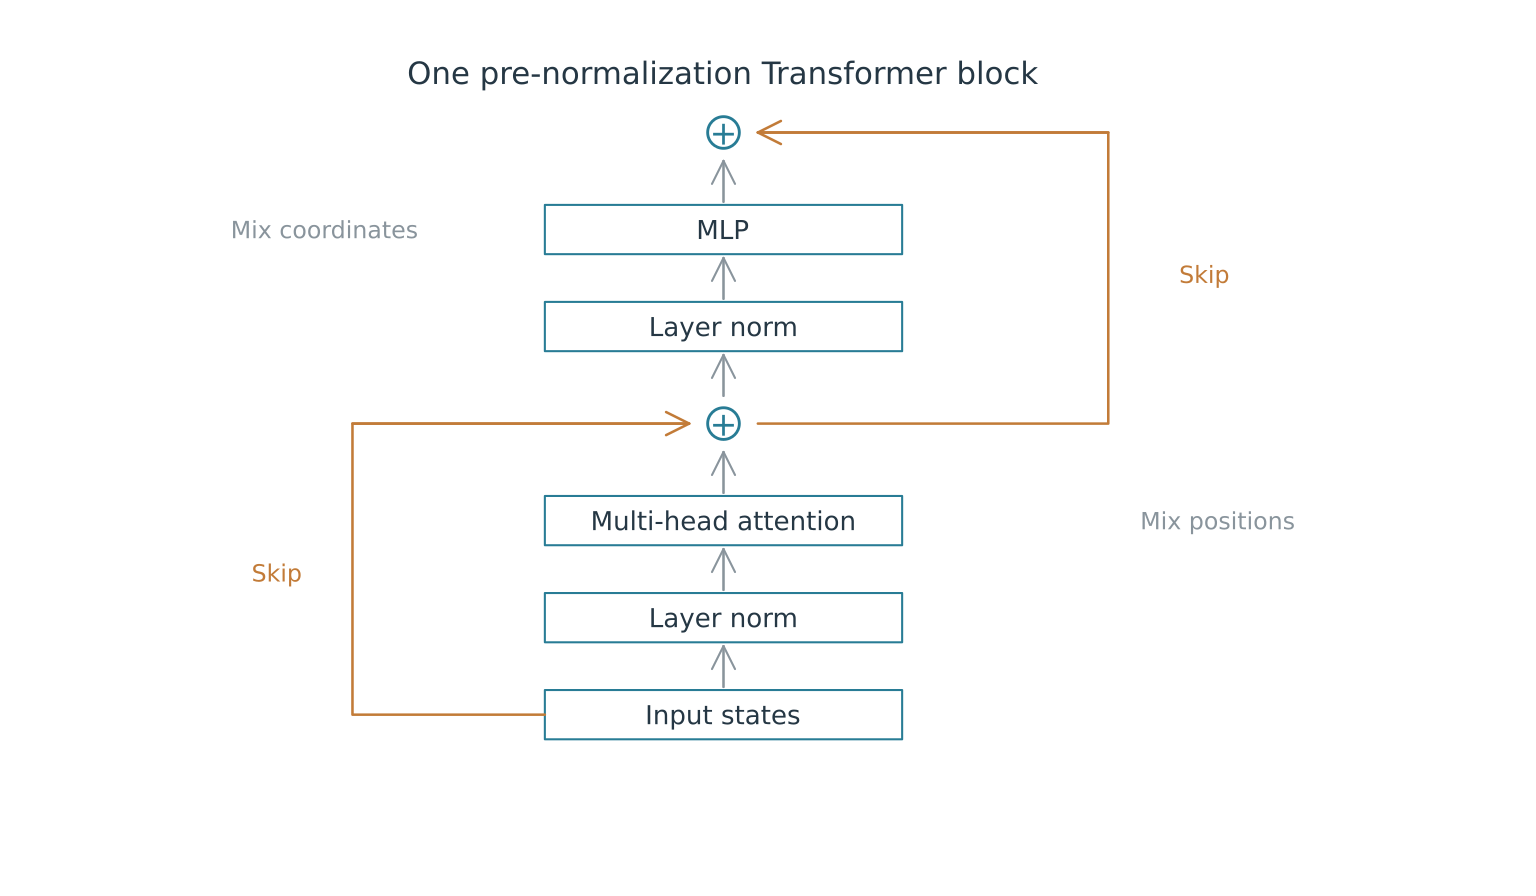

In [22]:
function block_diagram()
    p=plot(xlims=(0,10),ylims=(0,10),axis=false,grid=false,legend=false,size=(960,560))
    x=4.5
    ys=[1.1,2.4,3.7,5.0,6.3,7.6,8.9]
    labels=["Input states","Layer norm","Multi-head attention","+","Layer norm","MLP","+"]
    for (i,(y,label)) in enumerate(zip(ys,labels))
        if label=="+"
            scatter!(p,[x],[y];ms=11,color=:white,markerstrokecolor=TEAL,markerstrokewidth=1.6)
            annotate!(p,x,y,text("+",14,TEAL))
        else
            plot!(p,Shape([x-1.3,x+1.3,x+1.3,x-1.3],[y-.33,y-.33,y+.33,y+.33]);
                fillcolor=:white,linecolor=TEAL,lw=1.3)
            annotate!(p,x,y,text(label,11,INK))
        end
        i<length(ys) && plot!(p,[x,x],[y+.37,ys[i+1]-.38];color=GRAY,lw=1.3,arrow=true)
    end
    plot!(p,[x-1.3,1.8,1.8,x-.25],[1.1,1.1,5.0,5.0];color=AMBER,lw=1.6,arrow=true)
    plot!(p,[x+.25,7.3,7.3,x+.25],[5.0,5.0,8.9,8.9];color=AMBER,lw=1.6,arrow=true)
    annotate!(p,1.25,3.0,text("Skip",10,AMBER))
    annotate!(p,8.0,7.0,text("Skip",10,AMBER))
    annotate!(p,4.5,9.7,text("One pre-normalization Transformer block",13,INK))
    annotate!(p,8.1,3.7,text("Mix positions",10,GRAY))
    annotate!(p,1.6,7.6,text("Mix coordinates",10,GRAY))
    p
end
block_diagram()

*Figure 9. One full-width Transformer block. Orange paths implement the two additions in the formulas; they carry the original states around the learned sublayers. Every intermediate state at an addition has 256 coordinates per position.*

### 7.2 Inspect one real prefix inside this full model

The next cells take the first 12 BPE input positions from the actual training corpus,
with the 13th token as the observed target. They inspect **head 1 of block 1** in the
complete 5.82-million-parameter model at random initialization.
The calculations use all 256 input coordinates and all 32 coordinates of that head.
No separate attention model is trained.

Corpus prefix: Once upon a time there was a little boy named Ben
Observed next token: .
Normalized input (256, 12) | each W (32, 256) | each projected head (32, 12)


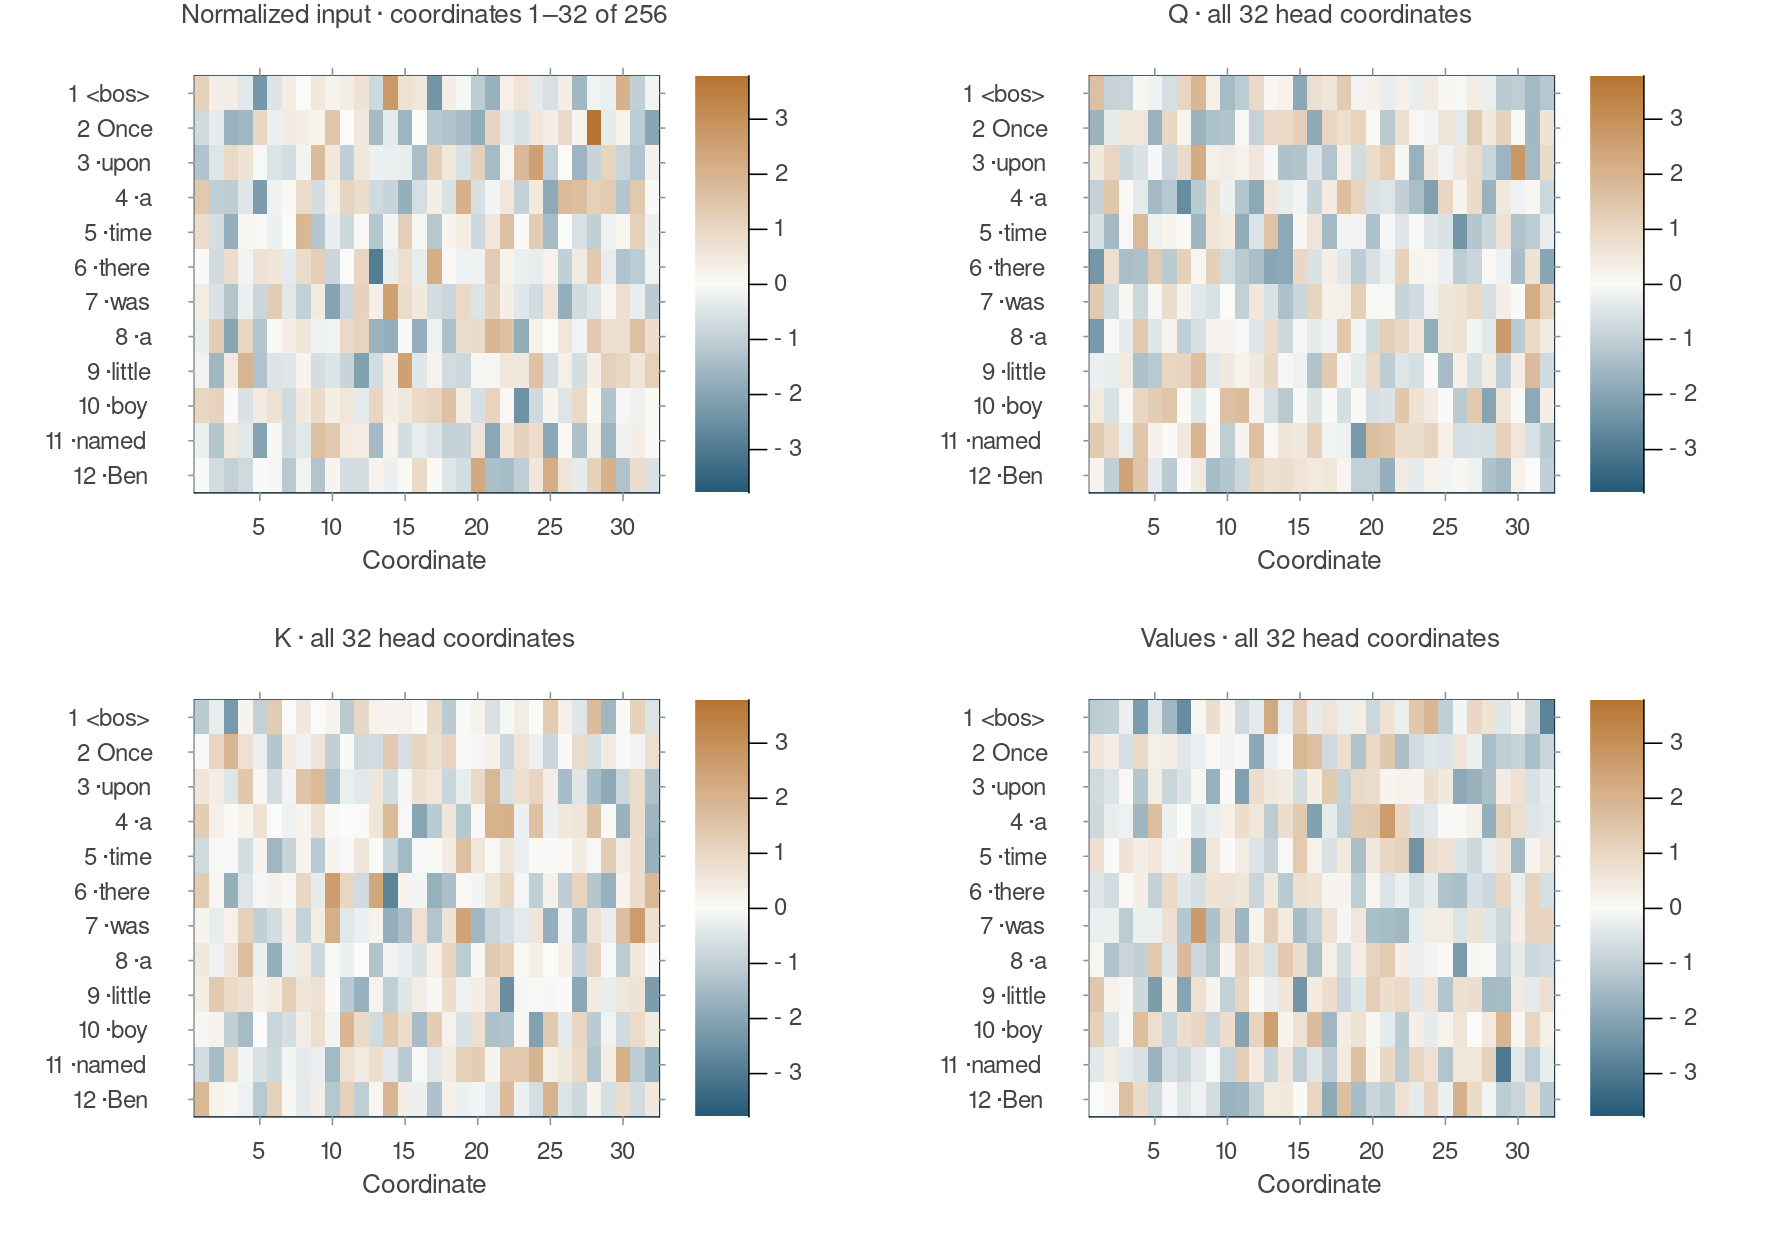

In [23]:
# A real corpus prefix; inspect head 1 of the full, randomly initialized GPT.
attention_sequence=Int.(story_tokens["train"][1:13])
attention_ids=attention_sequence[1:12]
target_id=attention_sequence[13]
attention_T=length(attention_ids)
attention_labels=[string(t," ",visible_token(tok.tokens[id])) for (t,id) in enumerate(attention_ids)]
input_states=gpt_initial.tokens(reshape(attention_ids,:,1)).+
    reshape(gpt_initial.positions(1:attention_T),256,attention_T,1)
first_block=gpt_initial.blocks[1]
attention_layer=first_block.attention
normalized_states=first_block.norm1(input_states)
head_coordinates=1:32
projection=(X=dropdims(normalized_states;dims=3),
    WQ=attention_layer.query.weight[head_coordinates,:],bQ=attention_layer.query.bias[head_coordinates],
    WK=attention_layer.key.weight[head_coordinates,:],bK=attention_layer.key.bias[head_coordinates],
    WV=attention_layer.value.weight[head_coordinates,:],bV=attention_layer.value.bias[head_coordinates])
Q=projection.WQ*projection.X.+projection.bQ
K=projection.WK*projection.X.+projection.bK
att_values=projection.WV*projection.X.+projection.bV
@assert size(Q)==size(K)==size(att_values)==(32,12)
println("Corpus prefix: ",bpe_decode(tok,attention_ids))
println("Observed next token: ",visible_token(tok.tokens[target_id]))
@printf("Normalized input %s | each W %s | each projected head %s\n",
    string(size(projection.X)),string(size(projection.WQ)),string(size(Q)))
# Plot a readable feature slice; all 256 input coordinates were used above.
lim=maximum(maximum(abs,M) for M in (projection.X[1:32,:],Q,K,att_values))
qplots=[matrix_panel(M';title=label,rowlabels=attention_labels,limit=lim)
    for (M,label) in [(projection.X[1:32,:],"Normalized input · coordinates 1–32 of 256"),
                     (Q,"Q · all 32 head coordinates"),(K,"K · all 32 head coordinates"),
                     (att_values,"Values · all 32 head coordinates")]]
plot(qplots...;layout=(2,2),size=(1120,780),titlefontsize=11)

*Figure 10. Actual arrays from the full model. The input panel displays coordinates 1–32 of 256 to keep its cells readable; all 256 participate in the multiplication. Each projected panel shows all 32 head coordinates. Rows in the display are token positions; Julia arrays store positions in columns.*

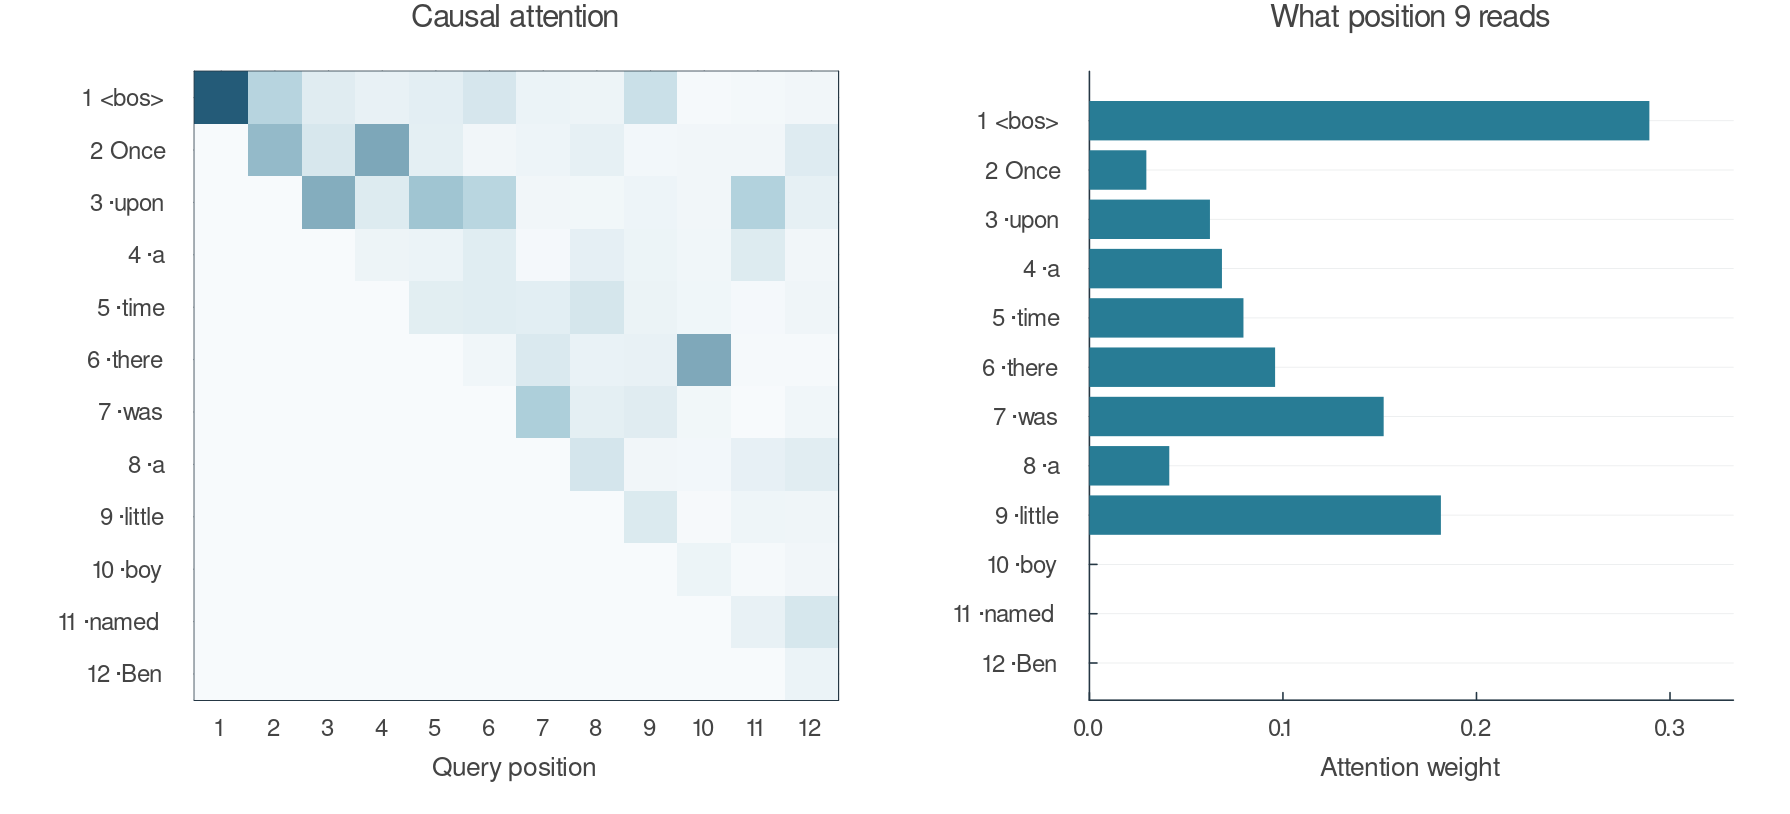

In [24]:
scores=K'*Q/sqrt(32f0)
attention_mask=causal_mask(attention_T)
A=Flux.softmax(scores.+attention_mask;dims=1)
O=att_values*A
@assert vec(sum(A;dims=1))≈ones(attention_T)
@assert all(iszero,A[tril(trues(attention_T,attention_T),-1)])
@assert O[:,end]≈sum(A[j,end].*att_values[:,j] for j in 1:attention_T)
ap=heatmap(1:attention_T,1:attention_T,A;color=SEQ,clims=(0,1),colorbar=false,
    xticks=(1:attention_T,1:attention_T),yticks=(1:attention_T,attention_labels),
    yflip=true,grid=false,framestyle=:box,xlabel="Query position",title="Causal attention")
query_at=9
bp=bar(1:attention_T,A[:,query_at];orientation=:horizontal,color=TEAL,
    linecolor=:transparent,label=false,yticks=(1:attention_T,attention_labels),yflip=true,
    xlabel="Attention weight",title="What position 9 reads",xlims=(0,1.15maximum(A[:,query_at])))
plot(ap,bp;layout=(1,2),size=(1120,510))

*Figure 11. A is a key-row/query-column matrix, so the forbidden future-key region is below the diagonal. Query 9 reads positions 1–9 and assigns exactly zero weight to positions 10–12.*

### 7.3 Backpropagate the full next-token loss through this head

The loss still uses all eight heads, all six blocks, and the vocabulary output layer.
Let $G_Z=\partial L/\partial Z$ for an intermediate matrix $Z$.
Automatic differentiation through the rest of the network supplies $G_O$ for this head.
We can then derive its local gradients explicitly.

From $O=\mathsf V A$,

$$G_{\mathsf V}=G_OA^\top,\qquad G_A=\mathsf V^\top G_O.$$

Within one query column $i$, the softmax Jacobian is
$\partial A_{ji}/\partial S_{\ell i}=A_{ji}(\mathbf1\{j=\ell\}-A_{\ell i})$.
Applying the chain rule and collecting terms gives

$$
(G_S)_{ji}
=\sum_\ell(G_A)_{\ell i}A_{\ell i}(\mathbf1\{\ell=j\}-A_{ji})
=A_{ji}\left[(G_A)_{ji}-\sum_\ell A_{\ell i}(G_A)_{\ell i}\right].
$$

Masked entries have $A_{ji}=0$, hence zero score gradient.
From $S=K^\top Q/\sqrt{32}$,

$$G_Q=KG_S/\sqrt{32},\qquad G_K=QG_S^\top/\sqrt{32}.$$

Finally, differentiate the affine projections:

$$
\begin{aligned}
G_{W_Q}&=G_Q\tilde X^\top,&G_{b_Q}&=G_Q\mathbf1_T,\\
G_{W_K}&=G_K\tilde X^\top,&G_{b_K}&=G_K\mathbf1_T,\\
G_{W_V}&=G_{\mathsf V}\tilde X^\top,&G_{b_V}&=G_{\mathsf V}\mathbf1_T.
\end{aligned}
$$

This head contributes the following gradient to the normalized input:

$$G_{\tilde X}^{(1)}
=W_Q^\top G_Q+W_K^\top G_K+W_V^\top G_{\mathsf V}.$$

The three terms add because the same input feeds all three projections.
The full network also sums contributions from the other heads and the residual path,
then differentiates normalization and the token-plus-position addition.
For that input addition, $x_t=E_{\rm LM}[:,i_t]+P[:,t]$, its gradient reaches both summands.
Repeated token IDs accumulate their contributions in the same embedding column.

The code checks these matrix derivatives, including biases, against automatic differentiation.
It also checks the head's query-weight gradient against backpropagation through the entire GPT.
A diagnostic update changes only this head's parameters; the input activation stays fixed.
The later training loop updates the complete model.

Manual / AD attention-gradient difference: 1.19e-07
Full-GPT next-token loss, updating only head 1: 7.008921 → 6.997778
Head-1 query gradients also match backpropagation through the entire GPT.


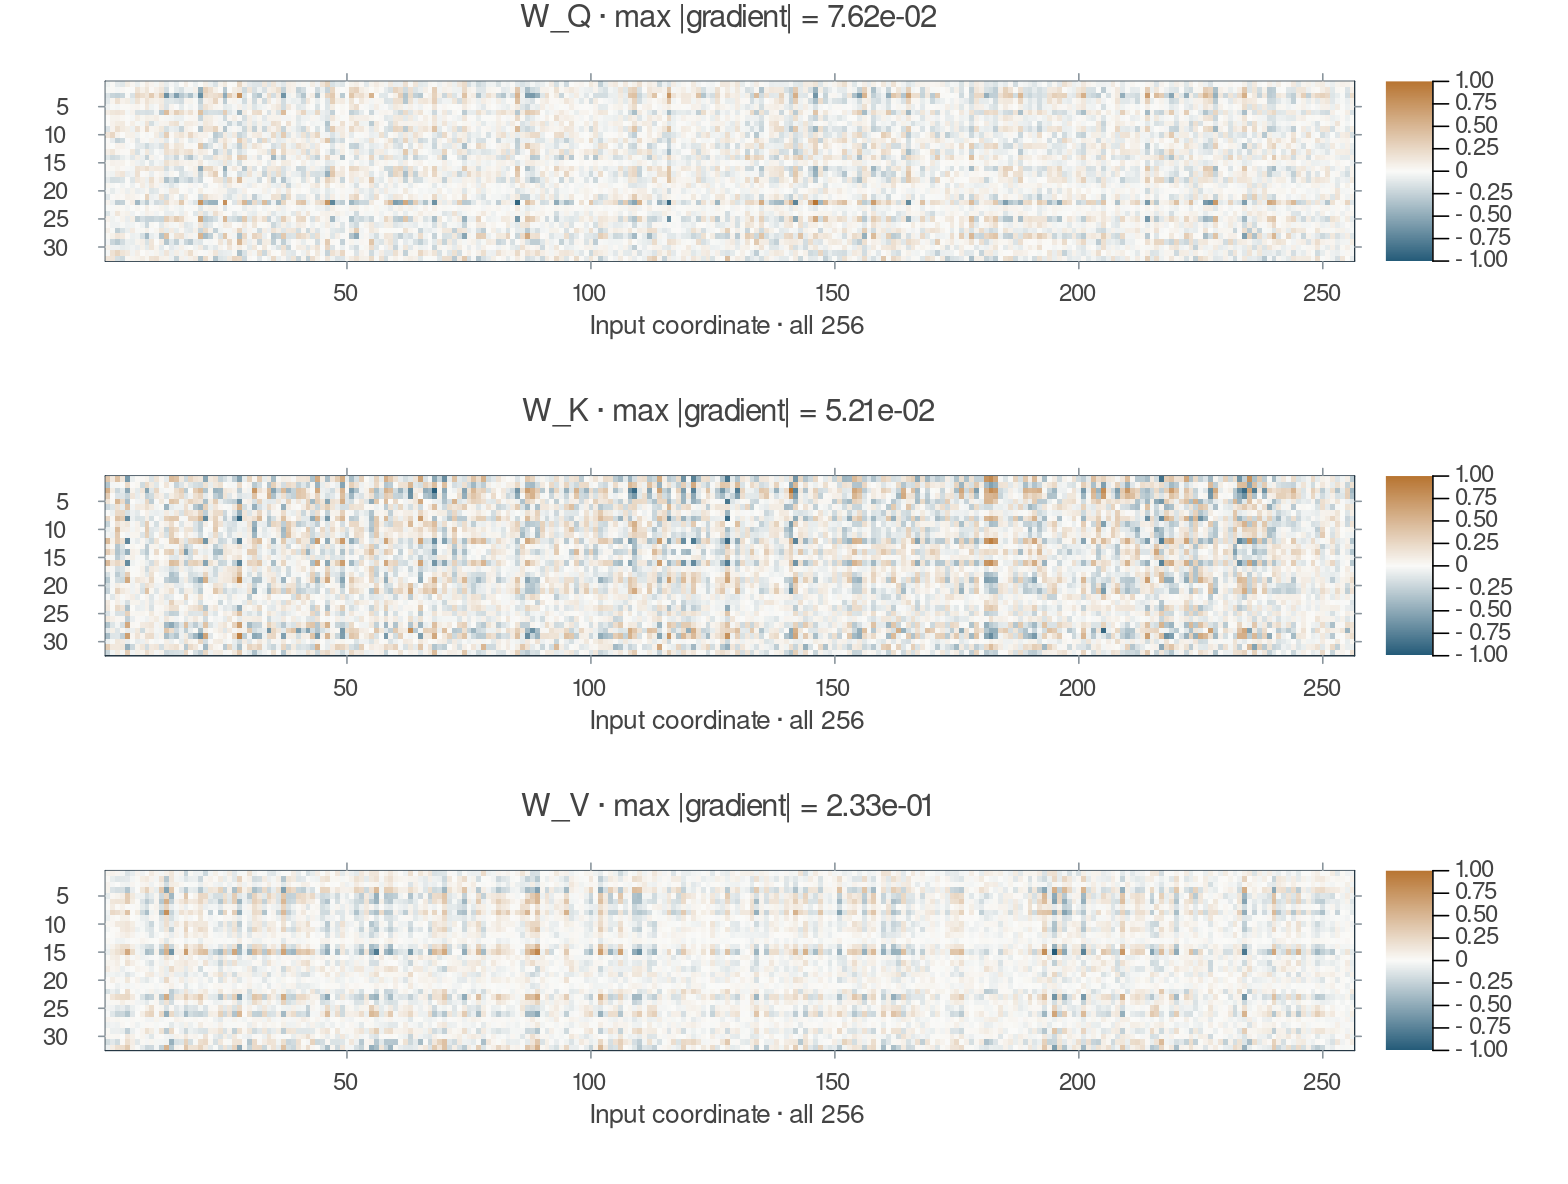

In [25]:
# Keep all eight heads and the rest of the full GPT in the loss calculation.
all_q=split_heads(attention_layer.query(normalized_states),8)
all_k=split_heads(attention_layer.key(normalized_states),8)
all_v=split_heads(attention_layer.value(normalized_states),8)
all_scores=Flux.NNlib.batched_mul(permutedims(all_k,(2,1,3)),all_q)/sqrt(32f0)
all_weights=Flux.softmax(all_scores.+reshape(attention_mask,attention_T,attention_T,1);dims=1)
all_outputs=Flux.NNlib.batched_mul(all_v,all_weights)
mixed_heads=reshape(permutedims(reshape(all_outputs,32,attention_T,8,1),(1,3,2,4)),256,attention_T)
@assert mixed_heads[1:32,:]≈O
function loss_after_first_attention(mixed)
    # Continue the actual first block, then every remaining block and output head.
    R=input_states+attention_layer.output(reshape(mixed,256,attention_T,1))
    X=R+first_block.feedforward(first_block.norm2(R))
    for block in gpt_initial.blocks[2:end]
        X=block(X,attention_mask)
    end
    logits=gpt_initial.head(gpt_initial.finalnorm(X))[:,end,1]
    -Flux.logsoftmax(logits)[target_id]
end
g_mixed=Flux.gradient(loss_after_first_attention,mixed_heads)[1]
g_O=g_mixed[1:32,:]
g_values=g_O*A';g_A=att_values'*g_O
g_scores=A.*(g_A.-sum(A.*g_A;dims=1))
g_Q=K*g_scores/sqrt(32f0);g_K=Q*g_scores'/sqrt(32f0)
qkv_manual=(X=projection.WQ'*g_Q+projection.WK'*g_K+projection.WV'*g_values,
    WQ=g_Q*projection.X',bQ=vec(sum(g_Q;dims=2)),
    WK=g_K*projection.X',bK=vec(sum(g_K;dims=2)),
    WV=g_values*projection.X',bV=vec(sum(g_values;dims=2)))
function loss_through_head(p)
    q=p.WQ*p.X.+p.bQ;k=p.WK*p.X.+p.bK;v=p.WV*p.X.+p.bV
    weights=Flux.softmax(k'*q/sqrt(32f0).+attention_mask;dims=1)
    loss_after_first_attention(vcat(v*weights,mixed_heads[33:end,:]))
end
qkv_ad=Flux.gradient(loss_through_head,projection)[1]
qkv_error=maximum(maximum(abs.(getproperty(qkv_manual,k).-getproperty(qkv_ad,k)))
    for k in keys(projection))
@assert qkv_error<1f-5
function full_prefix_loss(model)
    logits=gpt_logits(model,reshape(attention_ids,:,1),attention_mask,collect(1:attention_T))[:,end,1]
    -Flux.logsoftmax(logits)[target_id]
end
full_gradient=Flux.gradient(full_prefix_loss,gpt_initial)[1]
@assert loss_through_head(projection)≈full_prefix_loss(gpt_initial)
@assert isapprox(qkv_manual.WQ,full_gradient.blocks[1].attention.query.weight[1:32,:];atol=1f-5)
# Only parameters move in this diagnostic step; the activation X stays fixed.
step_size=0.001f0
projection_updated=merge(projection,(
    WQ=projection.WQ-step_size*qkv_ad.WQ,bQ=projection.bQ-step_size*qkv_ad.bQ,
    WK=projection.WK-step_size*qkv_ad.WK,bK=projection.bK-step_size*qkv_ad.bK,
    WV=projection.WV-step_size*qkv_ad.WV,bV=projection.bV-step_size*qkv_ad.bV))
@assert loss_through_head(projection_updated)<loss_through_head(projection)
@printf("Manual / AD attention-gradient difference: %.2e\n",qkv_error)
@printf("Full-GPT next-token loss, updating only head 1: %.6f → %.6f\n",
    loss_through_head(projection),loss_through_head(projection_updated))
println("Head-1 query gradients also match backpropagation through the entire GPT.")
gps=map([(:WQ,"W_Q"),(:WK,"W_K"),(:WV,"W_V")]) do (key,name)
    gradient=getproperty(qkv_ad,key);magnitude=maximum(abs,gradient)
    title=@sprintf("%s · max |gradient| = %.2e",name,magnitude)
    matrix_panel(gradient/magnitude;title,limit=1.0,xlabel="Input coordinate · all 256")
end
plot(gps...;layout=(3,1),size=(980,740))

*Figure 12. Gradients of the actual head's three 32 × 256 projection matrices. Colors divide each matrix by its own largest absolute entry, stated in the title; compare those numbers for magnitude. Optimization uses the original, unscaled gradients.*

**Encoder and decoder terminology.** An encoder can read the whole supplied input sequence.
In translation, a decoder can read an encoder's source representation and the target prefix.
GPT is decoder-only: its causal self-attention reads the available prefix.
These neural architectures differ from the tokenizer's text/ID encode and decode functions.

## 8. Train the full English model

The configuration stays fixed: vocabulary 2,048, width 256, six blocks, eight heads,
128-token training windows, and batches of eight windows.
The loss averages the $128\times8$ next-token targets in each training batch.

The complete loop below starts from random parameters, uses Adam and gradient clipping,
warms up the learning rate, and evaluates fixed training/validation windows.
It selects a checkpoint by validation loss. Test windows never select the checkpoint.
A 40-minute fit budget is checked between updates, with a reserve for evaluation.
This is not a hard process timeout.

In [26]:
function fit_gpt(train_ids,val_ids;V=2048,d=256,layers=6,heads=8,context=128,
                 batch_size=8,steps=100000,budget_seconds=2400,lr=0.0006f0,
                 seed=314159,device=identity,eval_every=50)
    started=time();Random.seed!(seed)
    config=(;V,d,layers,heads,context,batch_size,steps,budget_seconds,lr,seed)
    m=Flux.fmap(device,TinyGPT(V;d,layers,heads,context))
    rng=MersenneTwister(seed);eval_rng=MersenneTwister(991)
    positions=device(collect(1:context));mask=device(causal_mask(context))
    function batch(ids,rng)
        X,Y=token_batch(ids,context,batch_size,rng)
        device(X),device(Float32.(Flux.onehotbatch(vec(Y),1:V)))
    end
    batch_loss(model,X,Y)=Flux.logitcrossentropy(
        reshape(gpt_logits(model,X,mask,positions),V,:),Y)
    train_probe=[batch(train_ids,eval_rng) for _ in 1:3]
    val_probe=[batch(val_ids,eval_rng) for _ in 1:6]
    evaluate(model,bs)=mean(Float64(batch_loss(model,X,Y)) for (X,Y) in bs)
    tr,va=evaluate(m,train_probe),evaluate(m,val_probe)
    history=[(;step=0,seconds=time()-started,train_loss=tr,validation_loss=va)]
    best,best_loss,best_step=cpu_copy(m),va,0
    opt=Flux.setup(Flux.OptimiserChain(Flux.ClipNorm(1f0),Flux.Adam(lr)),m)
    last_step=0
    for step in 1:steps
        # Reserve time for final evaluation; budget is checked between updates.
        time()-started>=max(1,budget_seconds-30) && break
        fraction=clamp((time()-started)/max(1,budget_seconds-30),0,1)
        eta=Float32(lr*min(step/30,1)*(0.1+0.9*(1+cos(pi*fraction))/2))
        Flux.Optimisers.adjust!(opt,eta)
        X,Y=batch(train_ids,rng)
        value,g=Flux.withgradient(model->batch_loss(model,X,Y),m)
        @assert isfinite(value)
        Flux.update!(opt,m,g[1]);last_step=step
        if step%eval_every==0 || step==steps
            tr,va=evaluate(m,train_probe),evaluate(m,val_probe)
            push!(history,(;step,seconds=time()-started,train_loss=tr,validation_loss=va))
            if va<best_loss
                best,best_loss,best_step=cpu_copy(m),va,step
            end
            @printf("Step %d | %.1f s | train %.3f | validation %.3f\n",step,time()-started,tr,va)
        end
    end
    if history[end].step<last_step
        tr,va=evaluate(m,train_probe),evaluate(m,val_probe)
        push!(history,(;step=last_step,seconds=time()-started,train_loss=tr,validation_loss=va))
        if va<best_loss
            best,best_loss,best_step=cpu_copy(m),va,last_step
        end
    end
    (;weights=deepcopy(Flux.trainables(best)),config,history,best_step,seconds=time()-started)
end

The supplied model was trained from random initialization on this computer in about
38 minutes. Its saved arrays load into the exact model classes defined above.
The next cell checks that the restored model reproduces saved reference logits.

By default, `TRAIN_LARGE_GPT=false` inspects that recorded experiment.
Set it to true to run a fresh GPU fit with the same full-sized architecture and corpus.
The new result is saved under `output/nlp_course/`.
This compact trainer's warm-up and time-based schedule can differ from the recorded run;
it starts a fresh experiment rather than resuming an optimizer state.

In [27]:
saved=deserialize(joinpath(ROOT,"output","english_basics","notebook_weights.jls"))
c=saved.config
english_gpt=restore_weights!(TinyGPT(length(tok.tokens);d=c.d,layers=c.layers,
    heads=c.heads,context=c.context),saved.weights)
@assert saved.vocab==tok.tokens
probe=saved.probe
probe_T=size(probe.probe,1)
probe_error=maximum(abs.(gpt_logits(english_gpt,probe.probe,causal_mask(probe_T),
    collect(1:probe_T))-probe.logits))
@assert probe_error<1f-4
println("Saved English GPT: ",parameter_count(english_gpt)," parameters")
@printf("Loaded-weight verification: maximum logit difference %.2e\n",probe_error)
TRAIN_LARGE_GPT=false
if TRAIN_LARGE_GPT
    @eval using CUDA
    CUDA.allowscalar(false)
    CUDA.math_mode!(CUDA.FAST_MATH;precision=:TensorFloat32)
    fresh_run=fit_gpt(story_tokens["train"],story_tokens["validation"];
        d=256,layers=6,heads=8,context=128,steps=100000,budget_seconds=2400,
        lr=0.0006f0,device=CUDA.cu,eval_every=1000)
    serialize(joinpath(RESULTS,"fresh_large_gpt.jls"),fresh_run)
    english_gpt=restore_weights!(TinyGPT(length(tok.tokens);d=256,layers=6,
        heads=8,context=128),fresh_run.weights)
end

Saved English GPT: 5820416 parameters
Loaded-weight verification: maximum logit difference 0.00e+00


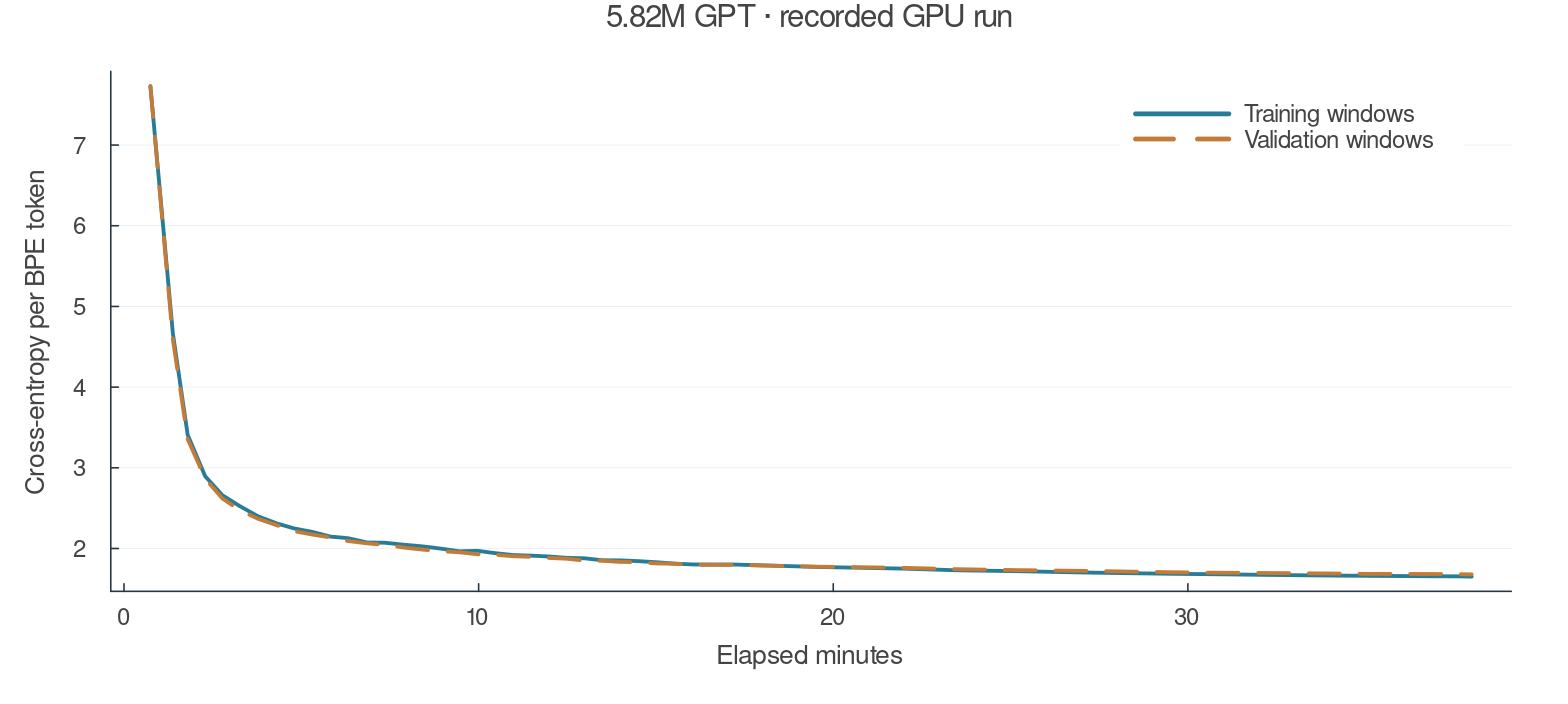

In [28]:
function language_curve(history,title;time_axis=false)
    x=time_axis ? [h.seconds/60 for h in history] : [h.step for h in history]
    p=plot(x,[h.train_loss for h in history];label="Training windows",color=TEAL,
        xlabel=time_axis ? "Elapsed minutes" : "Optimizer updates",ylabel="Cross-entropy per BPE token",title)
    plot!(p,x,[h.validation_loss for h in history];label="Validation windows",color=AMBER,linestyle=:dash)
    p
end
large_history=TRAIN_LARGE_GPT ? fresh_run.history : saved.history

plot(language_curve(large_history,TRAIN_LARGE_GPT ?
    "5.82M GPT · fresh GPU run" : "5.82M GPT · recorded GPU run";time_axis=true);size=(980,440))

*Figure 13. Learning curves of the full English model, labeled as the recorded GPU experiment or a newly requested GPU fit. Both curves measure fixed corpus windows; they do not measure general conversational ability.*

## 9. Evaluate and generate

### 9.1 Evaluate the same architecture before and after learning

We compare a newly initialized model with the trained model on the **same eight batches of
64-token test windows**, totaling 4,096 targets. Both have 5,820,416 parameters.
The random model is a same-architecture baseline, not a smaller model or an additional training run.

For the sampled test set $\mathcal T$, report mean cross-entropy and perplexity:

$$L_{\rm test}=-\frac1{|\mathcal T|}\sum_{(n,t)\in\mathcal T}\log p_{n,t}[y_{n,t}],
\qquad \operatorname{PPL}=\exp(L_{\rm test}).$$

These are sampled-window results, not an evaluation of every test token.
They are comparable because tokenizer, targets, and input windows are identical.
We also replace future input IDs and check that earlier logits remain unchanged.

In [29]:
function evaluate_language(m,batches)
    V=length(tok.tokens)
    mean(begin
        T=size(X,1)
        z=reshape(gpt_logits(m,X,causal_mask(T),collect(1:T)),V,:)
        Float64(Flux.logitcrossentropy(z,Flux.onehotbatch(vec(Y),1:V)))
    end for (X,Y) in batches)
end
test_rng=MersenneTwister(27182)
test_windows=[token_batch(story_tokens["test"],64,8,test_rng) for _ in 1:8]
initial_test_loss=evaluate_language(gpt_initial,test_windows)
large_test_loss=evaluate_language(english_gpt,test_windows)
@printf("%-14s %12s %12s %12s\n","Model","Parameters","Test loss","Perplexity")
@printf("%-14s %12d %12.4f %12.2f\n","Random start",parameter_count(gpt_initial),initial_test_loss,exp(initial_test_loss))
@printf("%-14s %12d %12.4f %12.2f\n","Trained GPT",parameter_count(english_gpt),large_test_loss,exp(large_test_loss))
# Earlier logits must not change when only future inputs are replaced.
check_ids=copy(test_windows[1][1][:,1:1])
base=gpt_logits(english_gpt,check_ids,causal_mask(64),collect(1:64))
changed=copy(check_ids);changed[33:end,:].=tok.bos
altered=gpt_logits(english_gpt,changed,causal_mask(64),collect(1:64))
@assert maximum(abs.(base[:,1:32,:]-altered[:,1:32,:]))<1f-4
println("Future-token isolation check passed.")

Model            Parameters    Test loss   Perplexity
Random start        5820416       7.7140      2239.55
Trained GPT         5820416       1.8635         6.45
Future-token isolation check passed.


### 9.2 Select a token and feed it back

During generation, learned parameters stay fixed. At each step:

1. Encode the prompt and calculate logits for its final position.
2. Divide logits by a positive temperature $\tau$ and apply softmax.
3. Select a token ID, append it to the input, and calculate the next distribution.
4. Stop at `<eos>` or the token limit, then decode the IDs.

The temperature-adjusted distribution is

$$p_\tau[k]=\frac{\exp(z[k]/\tau)}{\sum_j\exp(z[j]/\tau)}.$$

Lower $\tau$ concentrates probability on high scores; higher $\tau$ spreads it.
Greedy decoding selects the largest score.
For top-$k$ sampling, define $\mathcal K$ as the $k$ highest-scoring IDs and sample with

$$\tilde p[k]=\frac{\mathbf1\{k\in\mathcal K\}p_\tau[k]}
                   {\sum_{j\in\mathcal K}p_\tau[j]}.$$

Top-$p$ instead retains the smallest leading set whose cumulative probability reaches a chosen threshold.
Our code uses temperature and top-$k$.
A rolling window drops old tokens after the context fills; it does not extend the trained context length.
The displayed continuations are actual outputs, including repetitions and mistakes.

In [30]:
function generate_text(m,tok;prompt,seed=8,temperature=0.65,top_k=40,max_new=90)
    @assert temperature>0 && top_k>=1
    rng=MersenneTwister(seed)
    ids=vcat(tok.bos,bpe_encode(tok,prompt));generated=Int[]
    max_context=size(m.positions.weight,2);ended=false
    for _ in 1:max_new
        window=ids[max(1,length(ids)-max_context+1):end];T=length(window)
        z=vec(gpt_logits(m,reshape(window,:,1),causal_mask(T),collect(1:T))[:,end,1])
        z[tok.bos]=-Inf32;z[tok.unk]=-Inf32
        keep=partialsortperm(z,1:min(top_k,length(z));rev=true)
        p=Flux.softmax(z[keep]./Float32(temperature))
        next=keep[min(searchsortedfirst(cumsum(p),rand(rng)),length(keep))]
        if next==tok.eos
            ended=true;break
        end
        push!(generated,next);push!(ids,next)
    end
    (;prompt,continuation=bpe_decode(tok,generated),ended,tokens=length(generated))
end
prompts=["Once upon a time, there was a little",
    "The cat looked at the dog and said,","One day, a little girl found a"]
samples=[generate_text(english_gpt,tok;prompt,seed=7+i) for (i,prompt) in enumerate(prompts)]
for s in samples
    println("\nPROMPT: ",s.prompt,"\nCONTINUATION: ",s.continuation)
    println("Tokens generated: ",s.tokens," | ended at EOS: ",s.ended)
end
serialize(joinpath(RESULTS,"english_samples.jls"),samples)


PROMPT: Once upon a time, there was a little
CONTINUATION:  girl named Amy. She had a toy that she loved very much. She loved her toy so much that she played with it every day. One day, Amy saw her toy in the kitchen. It was a big bowl of yummy food. Amy wanted to eat the food, but it was too little. She tried to reach it, but she could not. She was sad and thought, "I will not eat the food." Amy had an idea
Tokens generated: 90 | ended at EOS: false

PROMPT: The cat looked at the dog and said,
CONTINUATION:  "Why are you so scared, dog?" The dog said, "I am too scared to fly. I am too small to fly and get hurt." The cat felt bad for the dog. The cat said, "I will help you. I am a magic cat. I can make your lives hurt." The dog thought for a moment. He decided to be brave. He walked and walked until he found a big tree. The magic cat
Tokens generated: 90 | ended at EOS: false

PROMPT: One day, a little girl found a
CONTINUATION:  pretty package. She was very happy and wanted to show i

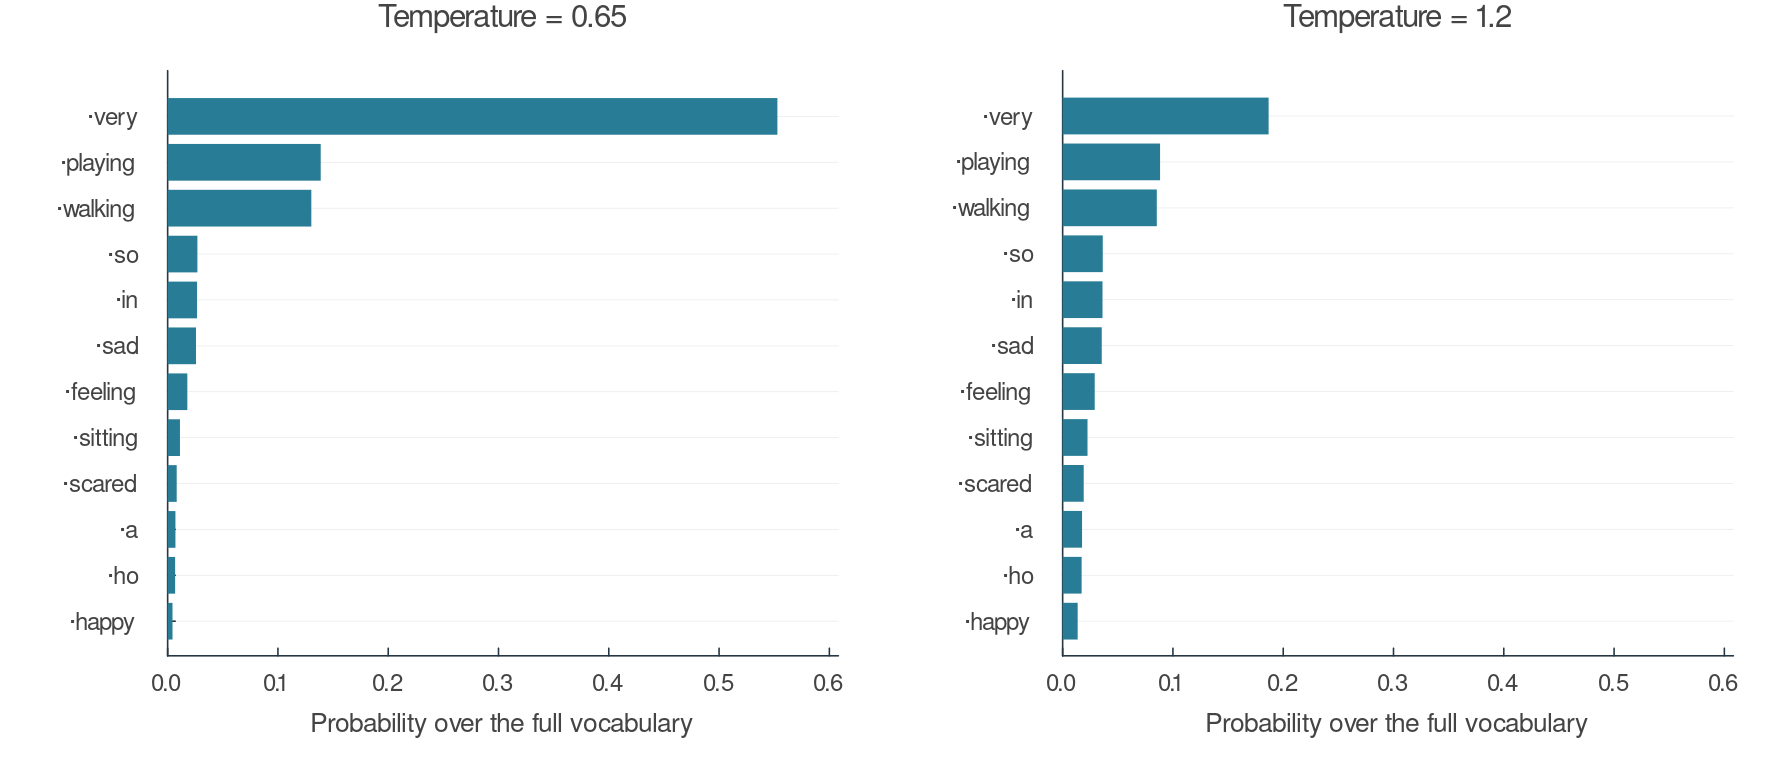

In [31]:
prefix=vcat(tok.bos,bpe_encode(tok,"The little cat was"))
T_prefix=length(prefix)
next_scores=vec(gpt_logits(english_gpt,reshape(prefix,:,1),causal_mask(T_prefix),
    collect(1:T_prefix))[:,end,1])
next_scores[tok.bos]=-Inf32;next_scores[tok.unk]=-Inf32
top_ids=partialsortperm(next_scores,1:12;rev=true)
token_labels=visible_token.(tok.tokens[top_ids])
temperatures=(0.65f0,1.2f0)
temperature_xmax=min(1.0,1.1maximum(maximum(Flux.softmax(next_scores./temp)) for temp in temperatures))
tps=map(temperatures) do temp
    p=Flux.softmax(next_scores./temp)
    bar(1:12,p[top_ids];orientation=:horizontal,label=false,color=TEAL,
        linecolor=:transparent,yticks=(1:12,token_labels),yflip=true,
        xlabel="Probability over the full vocabulary",xlims=(0,temperature_xmax),
        title="Temperature = $(temp)")
end
plot(tps...;layout=(1,2),size=(1120,480))

*Figure 14. The twelve highest-scoring next tokens for a fixed prompt under two temperatures, before top-k truncation. Probabilities use the full eligible vocabulary; beginning and unknown markers are suppressed by the sampler. Omitted tokens retain probability mass.*

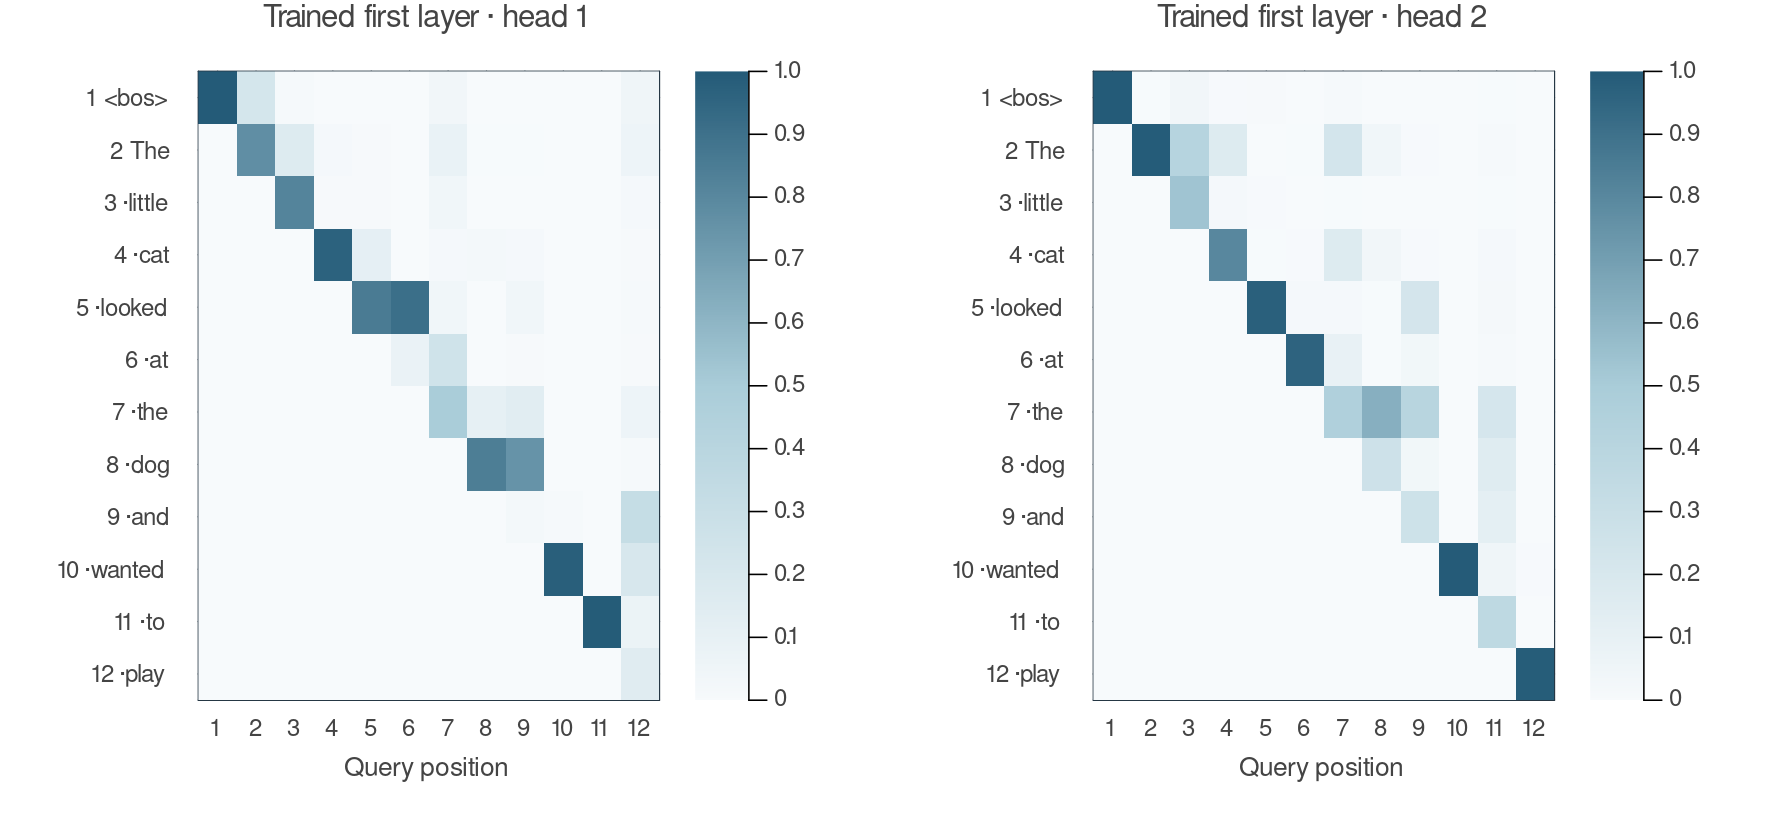

In [32]:
view_ids=vcat(tok.bos,bpe_encode(tok,"The little cat looked at the dog and wanted to play."))[1:12]
N=length(view_ids)
H=english_gpt.tokens(reshape(view_ids,:,1)).+reshape(english_gpt.positions(1:N),256,N,1)
first_block=english_gpt.blocks[1];a=first_block.attention
normalized=first_block.norm1(H)
q=split_heads(a.query(normalized),a.heads);k=split_heads(a.key(normalized),a.heads)
att_scores=Flux.NNlib.batched_mul(permutedims(k,(2,1,3)),q)/sqrt(32f0)
actual_attention=Flux.softmax(att_scores.+reshape(causal_mask(N),N,N,1);dims=1)
labels=[string(i," ",visible_token(tok.tokens[t])) for (i,t) in enumerate(view_ids)]
headplots=[heatmap(1:N,1:N,actual_attention[:,:,h];color=SEQ,clims=(0,1),colorbar=true,
    grid=false,framestyle=:box,yflip=true,xticks=(1:N,1:N),yticks=(1:N,labels),
    xlabel="Query position",title="Trained first layer · head $h") for h in 1:2]
plot(headplots...;layout=(1,2),size=(1120,510))

*Figure 15. Two measured first-layer heads in the trained full model. An attention weight is a mixture coefficient; by itself it is not a causal explanation of meaning.*

## 10. Check your understanding

1. What distinguishes a token position, a token ID, and an embedding coordinate?
2. What are $E$, $H$, $f$, and $a$? Derive $a=H\mathbf1_T/T=Ef$.
3. Which objects does the optimizer change, and which are recomputed activations?
4. Derive $\partial L/\partial z=\hat p-y$, then $\nabla_E L=\delta_a f^\top$.
5. Why must two reviews with the same word counts receive the same classifier prediction?
6. What are the shapes of a head's $W_Q$, $Q$, $K^\top Q$, and $\mathsf V A$?
7. Which axis of $A$ sums to one, and which entries must be zero?
8. Why must residual branches have matching shapes, and where does the direct gradient term come from?
9. Why can training process many positions together while generation chooses tokens sequentially?

<details><summary>Answer notes</summary>

A position identifies where a token occurs; its ID selects a vocabulary entry; a coordinate
selects a component of its vector. $E$ is the vocabulary table and $H$ selects its columns
with repetition. Averaging those columns equals weighting each vocabulary column by its
observed frequency $f_j$. Parameters persist and are updated; activations are recomputed.
The sigmoid and binary-loss derivatives simplify to $\hat p-y$; differentiating $a=Ef$
then gives $\delta_a f^\top$. Reordering leaves $f$ unchanged.
For the GPT head, the four shapes are $32\times256$, $32\times T$, $T\times T$, and $32\times T$.
Attention columns sum to one and future-key entries are zero.
Residual addition requires matching coordinates and positions;
differentiating $x+f(x)$ gives the identity plus the sublayer Jacobian.
Teacher forcing supplies all observed prefixes; generation must first choose the next token.

</details>

For a controlled experiment, change one setting at a time and keep the data split fixed.
Use validation to select checkpoints and evaluate test performance afterward.
Fluent-looking continuations alone do not establish factual accuracy or reliable reasoning.
Restart the kernel after changing model type definitions.

### Further reading

[Keras: Text classification from scratch](https://keras.io/examples/nlp/text_classification_from_scratch/),
[The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/), and
[Dive into Deep Learning](https://d2l.ai/chapter_natural-language-processing-applications/index.html)
provide complementary treatments.
The architecture and corpus references are
[Attention Is All You Need](https://arxiv.org/abs/1706.03762) and
[TinyStories](https://arxiv.org/abs/2305.07759).
The executable course uses Julia throughout.